# **Setup**

## **Imports**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    classification_report, precision_recall_curve
)
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.utils.class_weight import compute_class_weight

import shap
import lime
import lime.lime_tabular

## **Loading Data**

In [2]:
base_path = '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/'

circuits = pd.read_csv(base_path + 'circuits.csv')
constructor_results = pd.read_csv(base_path + 'constructor_results.csv')
constructor_standings = pd.read_csv(base_path + 'constructor_standings.csv')
constructors = pd.read_csv(base_path + 'constructors.csv')
driver_standings = pd.read_csv(base_path + 'driver_standings.csv')
drivers = pd.read_csv(base_path + 'drivers.csv')
lap_times = pd.read_csv(base_path + 'lap_times.csv')
pit_stops = pd.read_csv(base_path + 'pit_stops.csv')
qualifying = pd.read_csv(base_path + 'qualifying.csv')
races = pd.read_csv(base_path + 'races.csv')
results = pd.read_csv(base_path + 'results.csv')
seasons = pd.read_csv(base_path + 'seasons.csv')
sprint_results = pd.read_csv(base_path + 'sprint_results.csv')
status = pd.read_csv(base_path + 'status.csv')

In [3]:
tables = {
    'circuits': circuits,
    'constructor_results': constructor_results,
    'constructor_standings': constructor_standings,
    'constructors': constructors,
    'driver_standings': driver_standings,
    'drivers': drivers,
    'lap_times': lap_times,
    'pit_stops': pit_stops,
    'qualifying': qualifying,
    'races': races,
    'results': results,
    'seasons': seasons,
    'sprint_results': sprint_results,
    'status': status
}

# **Data Cleaning & Auditing**

## **Initial EDA**

Does the results table contain any duplicate driver race data?:  True
How many?  91
Driver-race combinations with duplicates: 85


Does the results table contain any duplicate car race data?:  True
How many?  164
Driver-car combinations with duplicates: 141


########### Missing Columns ####################

qualifying
q2    22
q3    46
dtype: int64


###################### Sentinel Columns ###################

constructor_results
status    12608
dtype: int64

drivers
number    802
code      757
dtype: int64

qualifying
q1     156
q2    4625
q3    6819
dtype: int64

races
time            731
fp1_date       1035
fp1_time       1057
fp2_date       1035
fp2_time       1057
fp3_date       1053
fp3_time       1072
quali_date     1035
quali_time     1057
sprint_date    1107
sprint_time    1110
dtype: int64

results
number                 6
position           10953
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fast

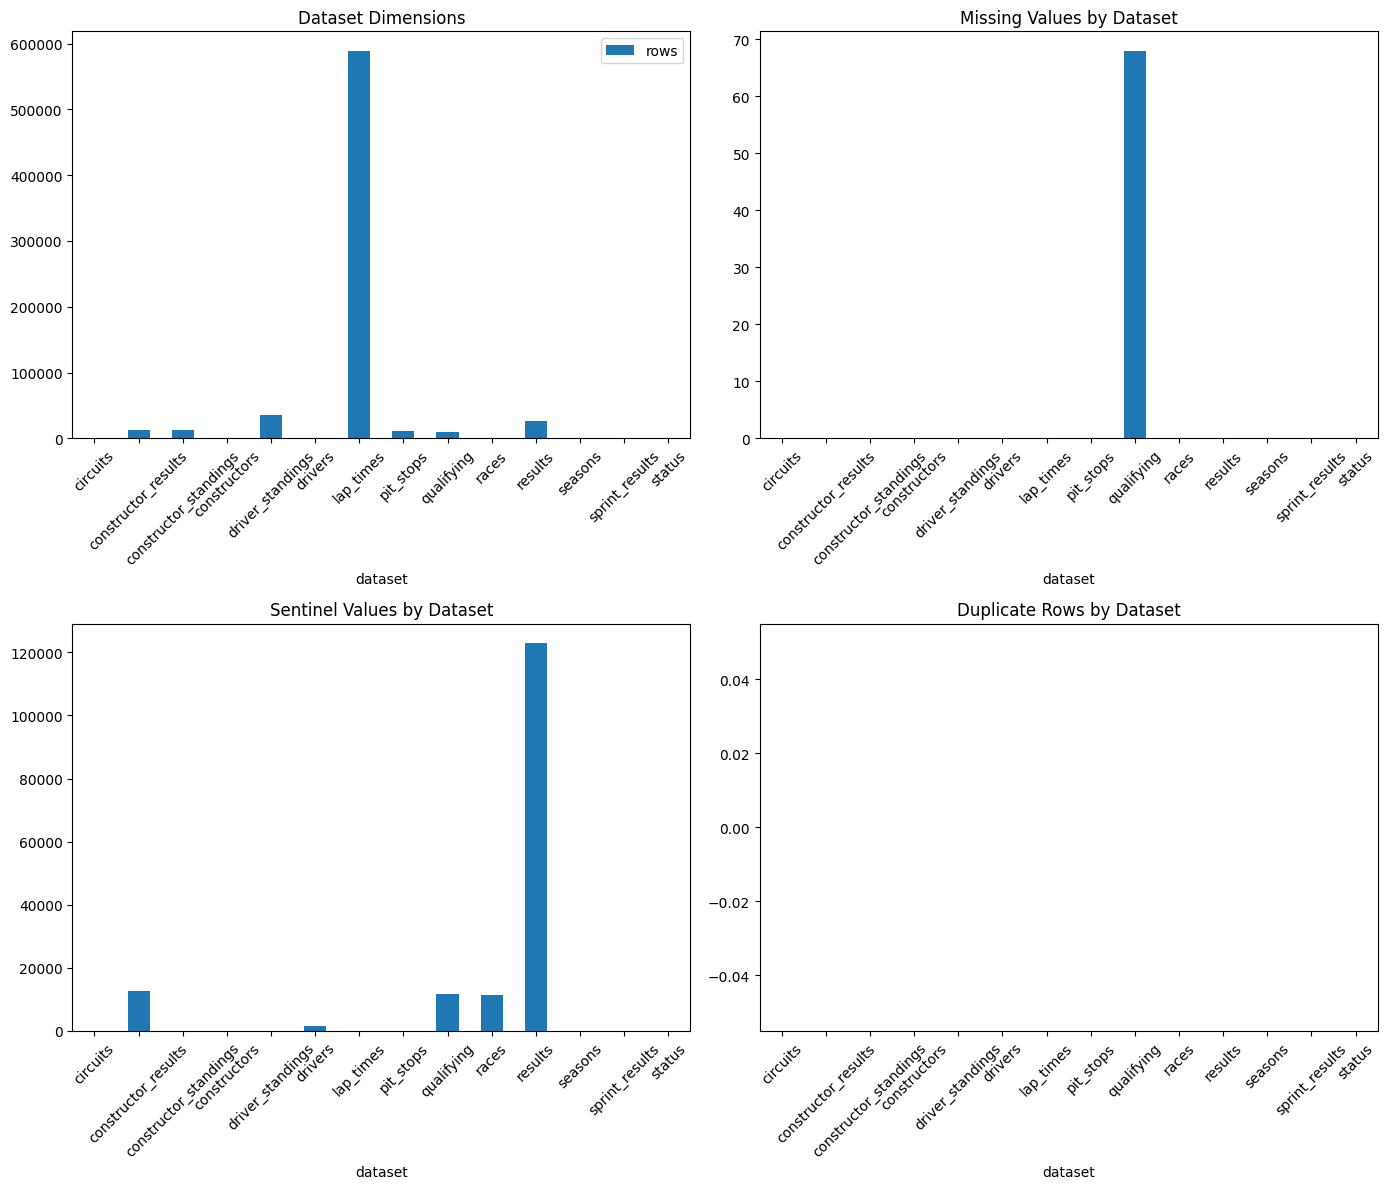

In [4]:
summary = []
missing = []
sentinels = []
duplicates = []

for name, df in tables.items():
    summary.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns)
    })
    
    missing.append({
        "dataset": name,
        "missing_values": df.isna().sum().sum()
    })
    
    sentinels.append({
        "dataset": name,
        "sentinel_values": (df == r"\N").sum().sum()
    })
    
    duplicates.append({
        "dataset": name,
        "duplicates": df.duplicated().sum()
    })


check = bool(tables['results'][['raceId', 'driverId']].duplicated().any())
number = tables['results'][['raceId', 'driverId']].duplicated().sum()
duplicate_groups = (
    tables['results'].groupby(["raceId", "driverId"])
    .size()
)
duplicate_groups = duplicate_groups[duplicate_groups > 1]

check_car_dupe = bool(tables['results'][['raceId', 'number']].duplicated().any())
number_car_dupe = tables['results'][['raceId', 'number']].duplicated().sum()
duplicate_cars_groups = (
    tables['results'].groupby(["raceId", "number"])
    .size()
)
duplicate_cars_groups = duplicate_cars_groups[duplicate_cars_groups > 1]

summary_df = pd.DataFrame(summary)
missing_df = pd.DataFrame(missing)
sentinels_df = pd.DataFrame(sentinels)
duplicates_df = pd.DataFrame(duplicates)

print('Does the results table contain any duplicate driver race data?: ', check)
print('How many? ', number)
print("Driver-race combinations with duplicates:", len(duplicate_groups))

print('\n')

print('Does the results table contain any duplicate car race data?: ', check_car_dupe)
print('How many? ', number_car_dupe)
print("Driver-car combinations with duplicates:", len(duplicate_cars_groups))

print('\n')

print('########### Missing Columns ####################')
for name, df in tables.items():
    missing_cols = df.isna().sum()
    missing_cols = missing_cols[missing_cols > 0]

    if len(missing_cols) > 0:
        print(f"\n{name}")
        print(missing_cols)

print('\n')

print('###################### Sentinel Columns ###################')
for name, df in tables.items():
    sentinel_cols = (df == r"\N").sum()
    sentinel_cols = sentinel_cols[sentinel_cols > 0]

    if len(sentinel_cols) > 0:
        print(f"\n{name}")
        print(sentinel_cols)

print('\n')

# Create a 2x2 grid of subplots with a shared figure size
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 12))

# 1. Dataset Dimensions (Top-Left)
summary_df.plot(
    x="dataset",
    y=["rows"],
    kind="bar",
    ax=axes[0, 0],
    title="Dataset Dimensions"
)

# 2. Missing Values (Top-Right)
missing_df.plot(
    x="dataset",
    y="missing_values",
    kind="bar",
    ax=axes[0, 1],
    title="Missing Values by Dataset",
    legend=False
)

# 3. Sentinel Values (Bottom-Left)
sentinels_df.plot(
    x="dataset",
    y="sentinel_values",
    kind="bar",
    ax=axes[1, 0],
    title="Sentinel Values by Dataset",
    legend=False
)

# 4. Duplicate Rows (Bottom-Right)
duplicates_df.plot(
    x="dataset",
    y="duplicates",
    kind="bar",
    ax=axes[1, 1],
    title="Duplicate Rows by Dataset",
    legend=False
)

# Rotate x-axis labels for readability and prevent overlapping titles/labels
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [5]:
for key, value in tables.items():
    print(f'###### {key} #######')
    print(value.info())
    print(value.describe())
    display(value.head(5))

###### circuits #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB
None
       circuitId        lat         lng          alt
count  77.000000  77.000000   77.000000    77.000000
mean   39.883117  33.442925    1.076683   247.012987
std    23.001701  22.808866   65.516951   362.738469
min     1.000000 -37.849700 -118.189000    -7.000000
25%    20.000000  32.777400   -9.394170    18.000000
50%    40.000000  40.951700    3.93083

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


###### constructor_results #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                12625 non-null  object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB
None
       constructorResultsId        raceId  constructorId        points
count          12625.000000  12625.000000   12625.000000  12625.000000
mean            8424.500594    528.235802      45.956119      4.053545
std             5666.310522    314.793555      59.468418      7.862202
min                1.000000      1.000000       1.000000      0.000000
25%             3157.000000    287.000000       6.000000      0.000000
50%  

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N
3,4,18,4,5.0,\N
4,5,18,5,2.0,\N


###### constructor_standings #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  object 
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB
None
       constructorStandingsId        raceId  constructorId        points  \
count            13391.000000  13391.000000   13391.000000  13391.000000   
mean             16982.110821    535.399821      49.603390     37.178515   
std               8868.446172    307.705928      61.213953     84.346048   
min  

...

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


###### sprint_results #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   resultId        360 non-null    int64 
 1   raceId          360 non-null    int64 
 2   driverId        360 non-null    int64 
 3   constructorId   360 non-null    int64 
 4   number          360 non-null    int64 
 5   grid            360 non-null    int64 
 6   position        360 non-null    object
 7   positionText    360 non-null    object
 8   positionOrder   360 non-null    int64 
 9   points          360 non-null    int64 
 10  laps            360 non-null    int64 
 11  time            360 non-null    object
 12  milliseconds    360 non-null    object
 13  fastestLap      360 non-null    object
 14  fastestLapTime  360 non-null    object
 15  statusId        360 non-null    int64 
dtypes: int64(10), object(6)
memory usage: 45.1+ KB
None
         resultI

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,25:38.426,1538426,14,1:30.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,+1.430,1539856,17,1:29.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,+7.502,1545928,17,1:29.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,+11.278,1549704,16,1:30.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,+24.111,1562537,16,1:30.566,1


###### status #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   statusId  139 non-null    int64 
 1   status    139 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.3+ KB
None
         statusId
count  139.000000
mean    71.237410
std     41.092434
min      1.000000
25%     35.500000
50%     72.000000
75%    106.500000
max    141.000000


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


## **String Normalization**

In [6]:
for column in df.columns:
    if(df[column].dtype == object):
        df[column] = df[column].str.strip()
        df[column] = df[column].replace(r'^\s*$', np.nan, regex=True)

## **Numerical Columns Casting**

In [7]:
cleaned_tables = {}

def convert_column_to_number(table):
    for column in table.columns:
        new_column = pd.to_numeric(table[column], errors='coerce')
        if new_column.notna().sum() == table[column].notna().sum():
            table[column] = new_column
    return table

# Convert Number Columns To Number Type After Removing \N 
for table_name,table in tables.items():
    cleaned_tables[table_name] = convert_column_to_number(table.replace("\\N", np.nan))

In [8]:
for key, value in cleaned_tables.items():
    print(f'###### {key} #######')
    print(value.info())
    display(value.head(5))

###### circuits #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB
None


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


###### constructor_results #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                17 non-null     object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB
None


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


###### constructor_standings #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  object 
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB
None


...

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


###### sprint_results #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    float64
 7   positionText    360 non-null    object 
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time            340 non-null    object 
 12  milliseconds    340 non-null    float64
 13  fastestLap      351 non-null    float64
 14  fastestLapTime  351 non-null    object 
 15  statusId        360 non-null    int64  
dtypes: float64(3), int64(10), object(3)
memory usage: 

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1.0,1,1,3,17,25:38.426,1538426.0,14.0,1:30.013,1
1,2,1061,1,131,44,1,2.0,2,2,2,17,+1.430,1539856.0,17.0,1:29.937,1
2,3,1061,822,131,77,3,3.0,3,3,1,17,+7.502,1545928.0,17.0,1:29.958,1
3,4,1061,844,6,16,4,4.0,4,4,0,17,+11.278,1549704.0,16.0,1:30.163,1
4,5,1061,846,1,4,6,5.0,5,5,0,17,+24.111,1562537.0,16.0,1:30.566,1


###### status #######
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   statusId  139 non-null    int64 
 1   status    139 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.3+ KB
None


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


## **Date Columns Casting**

In [9]:
# Convert Date Strings To Date Objects
cleaned_tables['races']['date'] = pd.to_datetime(cleaned_tables['races']['date'])
cleaned_tables['drivers']['dob'] = pd.to_datetime(cleaned_tables['drivers']['dob'])

## **Lap Times to Seconds Normalization**

In [10]:
# Convert Lap Times To Seconds
def time_to_seconds(text):
    if pd.isna(text):
        return np.nan
    minutes, seconds = text.split(':')
    return float(minutes) * 60 + float(seconds)


for col in ['q1', 'q2', 'q3']:
    cleaned_tables['qualifying'][col] = cleaned_tables['qualifying'][col].map(time_to_seconds)

In [11]:
cleaned_tables['qualifying'].head()

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,86.572,85.187,86.714
1,2,18,9,2,4,2,86.103,85.315,86.869
2,3,18,5,1,23,3,85.664,85.452,87.079
3,4,18,13,6,2,4,85.994,85.691,87.178
4,5,18,2,2,3,5,85.960,85.518,87.236


## **Referential Integrity**

In [12]:
# Create Composite Primary Keys
cleaned_tables['lap_times']['lapId'] = (cleaned_tables['lap_times']['raceId'].astype(str) + '_' + cleaned_tables['lap_times']['driverId'].astype(str) + '_' + cleaned_tables['lap_times']['lap'].astype(str))
cleaned_tables['pit_stops']['stopId'] = (cleaned_tables['pit_stops']['raceId'].astype(str) + '_' + cleaned_tables['pit_stops']['driverId'].astype(str) + '_' + cleaned_tables['pit_stops']['stop'].astype(str))

primary_keys = {
    'circuits': 'circuitId', 
    'constructor_results': 'constructorResultsId', 
    'constructor_standings': 'constructorStandingsId',
    'constructors': 'constructorId', 
    'driver_standings': 'driverStandingsId', 
    'drivers': 'driverId',
    'lap_times': 'lapId',
    'pit_stops': 'stopId',
    'qualifying': 'qualifyId', 
    'races': 'raceId',
    'results': 'resultId', 
    'seasons': 'year',
    'sprint_results': 'resultId',
    'status': 'statusId', 
}


for table_name, key in primary_keys.items():
    unique = cleaned_tables[table_name][key].is_unique
    no_missing = cleaned_tables[table_name][key].notna().all()
    print(f'{table_name}.{key}: \n unique = {unique} \n no missing = {no_missing}')

circuits.circuitId: 
 unique = True 
 no missing = True
constructor_results.constructorResultsId: 
 unique = True 
 no missing = True
constructor_standings.constructorStandingsId: 
 unique = True 
 no missing = True
constructors.constructorId: 
 unique = True 
 no missing = True
driver_standings.driverStandingsId: 
 unique = True 
 no missing = True
drivers.driverId: 
 unique = True 
 no missing = True
lap_times.lapId: 
 unique = True 
 no missing = True
pit_stops.stopId: 
 unique = True 
 no missing = True
qualifying.qualifyId: 
 unique = True 
 no missing = True
races.raceId: 
 unique = True 
 no missing = True
results.resultId: 
 unique = True 
 no missing = True
seasons.year: 
 unique = True 
 no missing = True
sprint_results.resultId: 
 unique = True 
 no missing = True
status.statusId: 
 unique = True 
 no missing = True


In [13]:
foreign_keys = [
    
    ('constructor_results', 'raceId', 'races', 'raceId'),
    ('constructor_results', 'constructorId', 'constructors', 'constructorId'),

    ('constructor_standings', 'raceId', 'races', 'raceId'),
    ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),

    ('driver_standings', 'raceId', 'races', 'raceId'),
    ('driver_standings', 'driverId', 'drivers', 'driverId'),

    ('lap_times', 'raceId', 'races', 'raceId'),
    ('lap_times', 'driverId', 'drivers', 'driverId'),

    
    ('pit_stops', 'raceId', 'races', 'raceId'),
    ('pit_stops', 'driverId', 'drivers', 'driverId'),

    ('qualifying', 'raceId', 'races', 'raceId'),
    ('qualifying', 'driverId', 'drivers', 'driverId'),
    ('qualifying', 'constructorId', 'constructors', 'constructorId'),

    ('races', 'circuitId', 'circuits', 'circuitId'),

    ('results', 'raceId', 'races', 'raceId'),
    ('results', 'driverId', 'drivers', 'driverId'),
    ('results', 'constructorId', 'constructors', 'constructorId'),
    ('results', 'statusId', 'status', 'statusId'),


    ('sprint_results', 'raceId', 'races', 'raceId'),
    ('sprint_results', 'driverId', 'drivers', 'driverId'),
    ('sprint_results', 'constructorId', 'constructors', 'constructorId'),
    ('sprint_results', 'statusId', 'status', 'statusId'),
    
]

for table, column, parent, parent_key in foreign_keys:
    # ~ means 'not'
    missing = ~ cleaned_tables[table][column].isin(cleaned_tables[parent][parent_key])
    print(f'{table}.{column} -> {parent}: {missing.sum()} values not found')

constructor_results.raceId -> races: 0 values not found
constructor_results.constructorId -> constructors: 0 values not found
constructor_standings.raceId -> races: 0 values not found
constructor_standings.constructorId -> constructors: 0 values not found
driver_standings.raceId -> races: 0 values not found
driver_standings.driverId -> drivers: 0 values not found
lap_times.raceId -> races: 0 values not found
lap_times.driverId -> drivers: 0 values not found
pit_stops.raceId -> races: 0 values not found
pit_stops.driverId -> drivers: 0 values not found
qualifying.raceId -> races: 0 values not found
qualifying.driverId -> drivers: 0 values not found
qualifying.constructorId -> constructors: 0 values not found
races.circuitId -> circuits: 0 values not found
results.raceId -> races: 0 values not found
results.driverId -> drivers: 0 values not found
results.constructorId -> constructors: 0 values not found
results.statusId -> status: 0 values not found
sprint_results.raceId -> races: 0 valu

## **Shared Drive Handling**

### **1 Driver 2 Cars**

In [14]:
# all duplicates
temporary_results = cleaned_tables['results']
duplicates = (
    temporary_results[
        temporary_results.duplicated(
            ['raceId', 'driverId'],
            keep=False
        )
    ]
    .sort_values(['raceId', 'driverId', 'positionOrder'])
)
duplicates

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
13188,13189,540,229,54,10.0,0,NaN,F,26,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81
13191,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97
17362,17363,717,373,172,1.0,1,7.0,7,7,0.0,102,NaN,NaN,NaN,NaN,NaN,NaN,60
24298,24304,717,373,172,2.0,1,NaN,R,12,0.0,54,NaN,NaN,NaN,NaN,NaN,NaN,98
17740,17741,733,465,172,48.0,0,NaN,W,22,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20142,20143,838,627,154,20.0,6,NaN,R,12,0.0,10,NaN,NaN,NaN,NaN,NaN,NaN,25
20183,20184,839,579,51,60.0,7,NaN,R,13,0.0,34,NaN,NaN,NaN,NaN,NaN,NaN,5
20163,20164,839,579,51,18.0,1,NaN,R,15,1.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6
20182,20183,839,647,6,48.0,6,2.0,2,2,3.0,80,NaN,NaN,NaN,NaN,NaN,NaN,1


In [15]:
# we chose to keep best position order as it is the entry most likely to finish the race 
sorted_results = temporary_results.sort_values(
    ['raceId', 'driverId', 'positionOrder']
)

filtered_duplicates = sorted_results[
    sorted_results.duplicated(
        ['raceId', 'driverId'],
        keep='first'
    )
]

filtered_duplicates

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
13191,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97
24298,24304,717,373,172,2.0,1,NaN,R,12,0.0,54,NaN,NaN,NaN,NaN,NaN,NaN,98
17743,17744,733,465,97,50.0,0,NaN,W,25,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
17963,17964,742,475,172,28.0,5,NaN,R,21,0.0,44,NaN,NaN,NaN,NaN,NaN,NaN,23
18062,18063,745,418,172,22.0,11,NaN,R,17,0.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19997,19998,831,642,51,34.0,2,NaN,R,16,0.0,6,NaN,NaN,NaN,NaN,NaN,NaN,5
20096,20097,835,529,150,14.0,8,NaN,R,31,0.0,30,NaN,NaN,NaN,NaN,NaN,NaN,67
20142,20143,838,627,154,20.0,6,NaN,R,12,0.0,10,NaN,NaN,NaN,NaN,NaN,NaN,25
20163,20164,839,579,51,18.0,1,NaN,R,15,1.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6


In [16]:
cleaned_tables['results'] = temporary_results.drop(
    filtered_duplicates.index
)

cleaned_tables['results']

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26754,26760,1144,825,210,20.0,14,16.0,16,16,0.0,57,NaN,NaN,57.0,1.0,1:25.637,222.002,11
26755,26761,1144,859,215,30.0,12,17.0,17,17,0.0,55,NaN,NaN,52.0,12.0,1:28.751,214.212,5
26756,26762,1144,822,15,77.0,9,NaN,R,18,0.0,30,NaN,NaN,14.0,19.0,1:29.482,212.462,130
26757,26763,1144,861,3,43.0,20,NaN,R,19,0.0,26,NaN,NaN,5.0,17.0,1:29.411,212.631,5


### **1 Car 2 Drivers**

In [17]:
# all duplicates
temporary_results = cleaned_tables['results']
duplicates = (
    temporary_results[
        temporary_results.duplicated(
            ['raceId', 'number'],
            keep=False
        )
    ]
    .sort_values(['raceId', 'number', 'positionOrder'])
)
duplicates

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
11576,11577,484,176,57,14.0,18,4.0,4,4,3.0,62,+1:17.03,7300690.0,NaN,NaN,NaN,NaN,1
11602,11603,484,218,57,14.0,0,NaN,W,30,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
12290,12291,508,191,21,30.0,0,NaN,F,27,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81
12292,12293,508,200,21,30.0,0,NaN,W,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
12725,12726,525,217,182,5.0,17,7.0,7,7,0.0,68,NaN,NaN,NaN,NaN,NaN,NaN,14
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20181,20182,838,627,154,26.0,15,6.0,6,6,0.0,56,NaN,NaN,NaN,NaN,NaN,NaN,18
20150,20151,839,802,6,48.0,6,2.0,2,2,3.0,80,+1:18.6,10356000.0,NaN,NaN,NaN,NaN,1
20182,20183,839,647,6,48.0,6,2.0,2,2,3.0,80,NaN,NaN,NaN,NaN,NaN,NaN,1
20161,20162,839,641,51,60.0,7,NaN,R,13,0.0,34,NaN,NaN,NaN,NaN,NaN,NaN,5


In [18]:
# we chose to keep best position order as it is the entry most likely to finish the race 
sorted_results = temporary_results.sort_values(
    ['raceId', 'number', 'positionOrder']
)

filtered_duplicates = sorted_results[
    sorted_results.duplicated(
        ['raceId', 'number'],
        keep='first'
    )
]

filtered_duplicates

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
11602,11603,484,218,57,14.0,0,NaN,W,30,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
12292,12293,508,200,21,30.0,0,NaN,W,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
12748,12749,525,182,182,5.0,0,NaN,W,30,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
13392,13393,548,223,57,22.0,0,NaN,F,24,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81
13485,13486,551,175,63,18.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20179,20180,835,803,161,24.0,17,NaN,R,27,0.0,108,NaN,NaN,NaN,NaN,NaN,NaN,51
20180,20181,838,774,154,16.0,4,5.0,5,5,1.0,59,NaN,NaN,NaN,NaN,NaN,NaN,15
20181,20182,838,627,154,26.0,15,6.0,6,6,0.0,56,NaN,NaN,NaN,NaN,NaN,NaN,18
20182,20183,839,647,6,48.0,6,2.0,2,2,3.0,80,NaN,NaN,NaN,NaN,NaN,NaN,1


In [19]:
cleaned_tables['results'] = temporary_results.drop(
    filtered_duplicates.index
)

cleaned_tables['results']

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26754,26760,1144,825,210,20.0,14,16.0,16,16,0.0,57,NaN,NaN,57.0,1.0,1:25.637,222.002,11
26755,26761,1144,859,215,30.0,12,17.0,17,17,0.0,55,NaN,NaN,52.0,12.0,1:28.751,214.212,5
26756,26762,1144,822,15,77.0,9,NaN,R,18,0.0,30,NaN,NaN,14.0,19.0,1:29.482,212.462,130
26757,26763,1144,861,3,43.0,20,NaN,R,19,0.0,26,NaN,NaN,5.0,17.0,1:29.411,212.631,5


## **Post Cleaning EDA**

Does the results table contain any duplicate race data?:  False
How many?  0
Driver-race combinations with duplicates: 0


Does the results table contain any duplicate car race data?:  False
How many?  0
Driver-car combinations with duplicates: 0



########### Missing Columns ####################

constructor_results
status    12608
dtype: int64

drivers
number    802
code      757
dtype: int64

qualifying
q1     156
q2    4647
q3    6865
dtype: int64

races
time            731
fp1_date       1035
fp1_time       1057
fp2_date       1035
fp2_time       1057
fp3_date       1053
fp3_time       1072
quali_date     1035
quali_time     1057
sprint_date    1107
sprint_time    1110
dtype: int64

results
number                 3
position           10808
time               18874
milliseconds       18874
fastestLap         18279
rank               18021
fastestLapTime     18279
fastestLapSpeed    18279
dtype: int64

sprint_results
position          15
time              20
milliseconds      20
fa

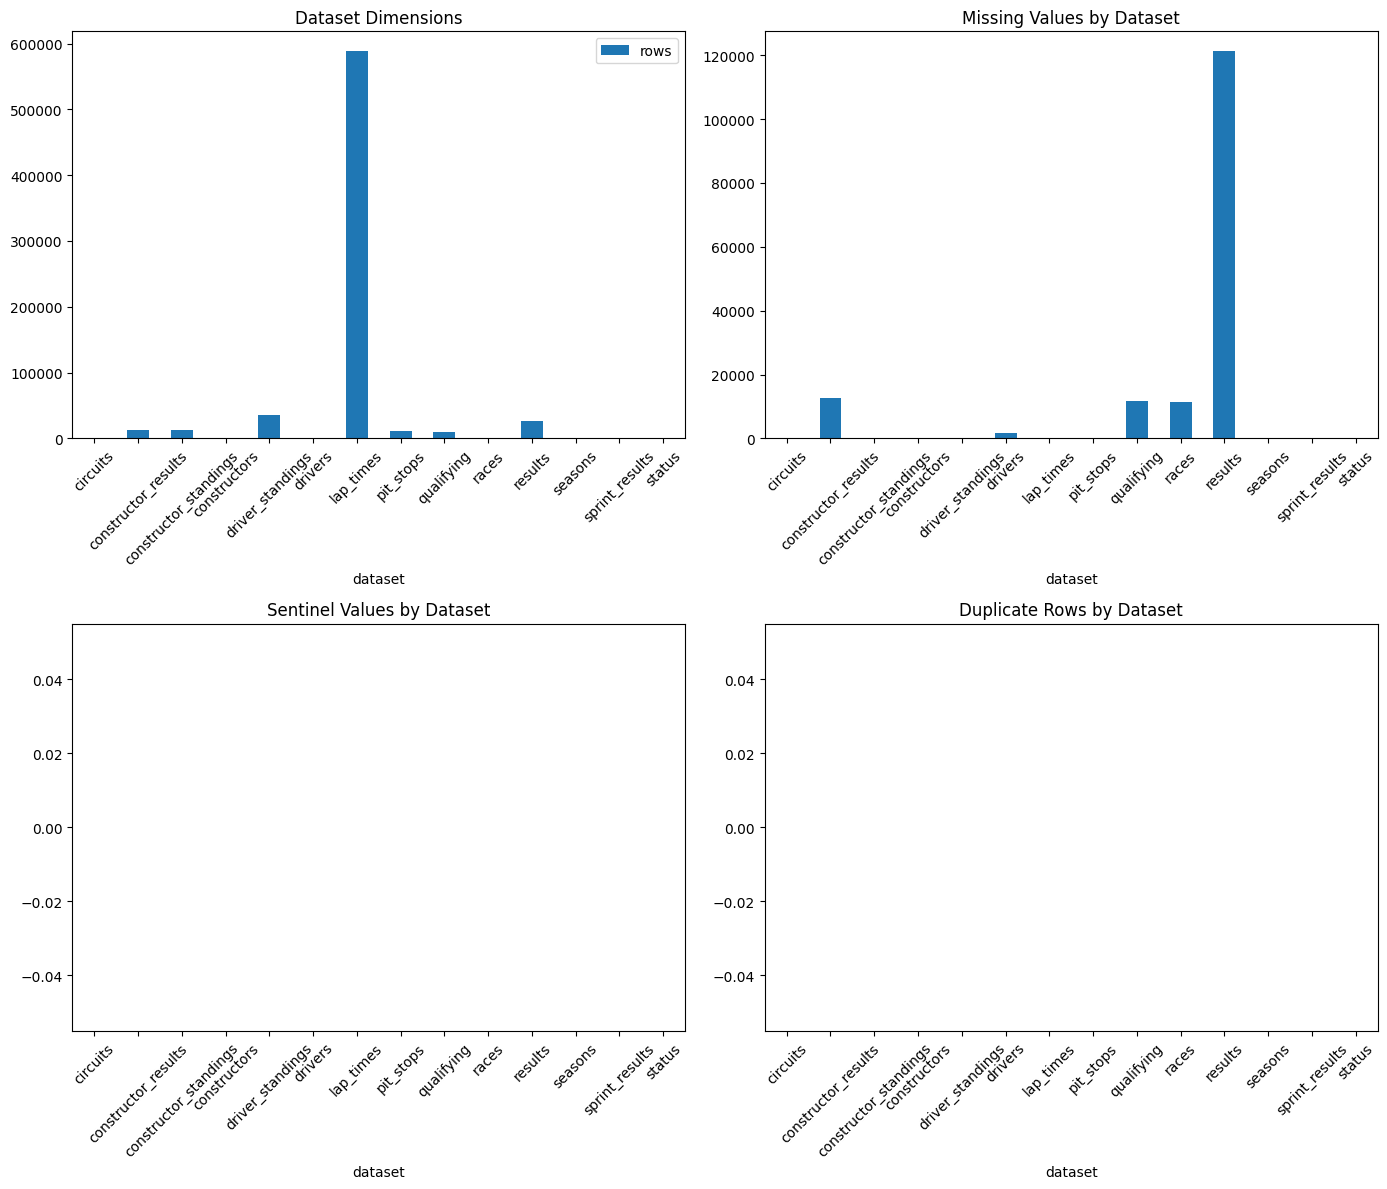

In [20]:
summary = []
missing = []
sentinels = []
duplicates = []

for name, df in cleaned_tables.items():
    summary.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns)
    })

    missing.append({
        "dataset": name,
        "missing_values": df.isna().sum().sum()
    })

    sentinels.append({
        "dataset": name,
        "sentinel_values": (df == r"\N").sum().sum()
    })

    duplicates.append({
        "dataset": name,
        "duplicates": df.duplicated().sum()
    })


check = cleaned_tables['results'][['raceId', 'driverId']].duplicated().any()
number = cleaned_tables['results'][['raceId', 'driverId']].duplicated().sum()
duplicate_groups = (
    cleaned_tables['results'].groupby(["raceId", "driverId"])
    .size()
)
duplicate_groups = duplicate_groups[duplicate_groups > 1]

check_car_dupe = bool(cleaned_tables['results'][['raceId', 'number']].duplicated().any())
number_car_dupe = cleaned_tables['results'][['raceId', 'number']].duplicated().sum()
duplicate_cars_groups = (
    cleaned_tables['results'].groupby(["raceId", "number"])
    .size()
)
duplicate_cars_groups = duplicate_cars_groups[duplicate_cars_groups > 1]

summary_df = pd.DataFrame(summary)
missing_df = pd.DataFrame(missing)
sentinels_df = pd.DataFrame(sentinels)
duplicates_df = pd.DataFrame(duplicates)


print('Does the results table contain any duplicate race data?: ', check)
print('How many? ', number)
print("Driver-race combinations with duplicates:", len(duplicate_groups))

print('\n')

print('Does the results table contain any duplicate car race data?: ', check_car_dupe)
print('How many? ', number_car_dupe)
print("Driver-car combinations with duplicates:", len(duplicate_cars_groups))

print('\n')

print('')
print('########### Missing Columns ####################')
for name, df in cleaned_tables.items():
    missing_cols = df.isna().sum()
    missing_cols = missing_cols[missing_cols > 0]

    if len(missing_cols) > 0:
        print(f"\n{name}")
        print(missing_cols)

print("")
print('###################### Sentinel Columns ###################')
for name, df in cleaned_tables.items():
    sentinel_cols = (df == r"\N").sum()
    sentinel_cols = sentinel_cols[sentinel_cols > 0]

    if len(sentinel_cols) > 0:
        print(f"\n{name}")
        print(sentinel_cols)


# Create a 2x2 grid of subplots with a shared figure size
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 12))

# 1. Dataset Dimensions (Top-Left)
summary_df.plot(
    x="dataset",
    y=["rows"],
    kind="bar",
    ax=axes[0, 0],
    title="Dataset Dimensions"
)

# 2. Missing Values (Top-Right)
missing_df.plot(
    x="dataset",
    y="missing_values",
    kind="bar",
    ax=axes[0, 1],
    title="Missing Values by Dataset",
    legend=False
)

# 3. Sentinel Values (Bottom-Left)
sentinels_df.plot(
    x="dataset",
    y="sentinel_values",
    kind="bar",
    ax=axes[1, 0],
    title="Sentinel Values by Dataset",
    legend=False
)

# 4. Duplicate Rows (Bottom-Right)
duplicates_df.plot(
    x="dataset",
    y="duplicates",
    kind="bar",
    ax=axes[1, 1],
    title="Duplicate Rows by Dataset",
    legend=False
)

# Rotate x-axis labels for readability and prevent overlapping titles/labels
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [21]:
# for name, table in cleaned_tables.items():
#     print(f"=========== {name} ===========")
#     display(table.head(1))

display(cleaned_tables['races'].head(1))
display(cleaned_tables['circuits'].head(1))
display(cleaned_tables['results'].head(1))
display(cleaned_tables['drivers'].head(1))
display(cleaned_tables['constructor_standings'].head(1))

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.8497,144.968,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.3,1


,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44.0,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton


,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1


# **Data Engineering Questions**

## **Which circuits convert a front-row start into a podium most often, and does that ranking change after the 2014 hybrid era? Distinguish qualifying position from grid (which can differ due to penalties).**

In [22]:
mask = (cleaned_tables['results']['grid'] <= 2) & (cleaned_tables['results']['position'] <= 3)

merged_before_2014 = (
    cleaned_tables['results'][mask]
    .merge(cleaned_tables['races'][cleaned_tables['races']['year'] < 2014][['raceId', 'circuitId']], on='raceId')
    .merge(cleaned_tables['circuits'][['circuitId', 'name']], on='circuitId')
)

merged_after_2014 = (
    cleaned_tables['results'][mask]
    .merge(cleaned_tables['races'][cleaned_tables['races']['year'] >= 2014][['raceId', 'circuitId']], on='raceId')
    .merge(cleaned_tables['circuits'][['circuitId', 'name']], on='circuitId')
)

df_before_2014 = (
    merged_before_2014.groupby('name')
    .size()
    .sort_values(ascending=False)
    .rename('num')
    .reset_index()
    .rename(columns={'name': 'circuit'})
)



df_after_2014 = (
    merged_after_2014.groupby('name')
    .size()
    .sort_values(ascending=False)
    .rename('num')
    .reset_index()
    .rename(columns={'name': 'circuit'})
)

print(f"=====================================================")
print(f"BEFORE 2014")
display(df_before_2014)
print(f"=====================================================")
print(f"=====================================================")
print(f"AFTER 2014")
display(df_after_2014)
print(f"=====================================================")

BEFORE 2014


,circuit,num
0,Autodromo Nazionale di Monza,60
1,Circuit de Monaco,59
2,Silverstone Circuit,53
3,Circuit de Spa-Francorchamps,49
4,Nürburgring,45
...,...,...
62,Le Mans,1
63,Monsanto Park Circuit,1
64,Montjuïc,1
65,Las Vegas Street Circuit,1


AFTER 2014


,circuit,num
0,Red Bull Ring,19
1,Yas Marina Circuit,19
2,Circuit de Barcelona-Catalunya,18
3,Circuit de Spa-Francorchamps,18
4,Silverstone Circuit,18
5,Circuit de Monaco,17
6,Circuit of the Americas,16
7,Autodromo Nazionale di Monza,16
8,Suzuka Circuit,16
9,Bahrain International Circuit,16


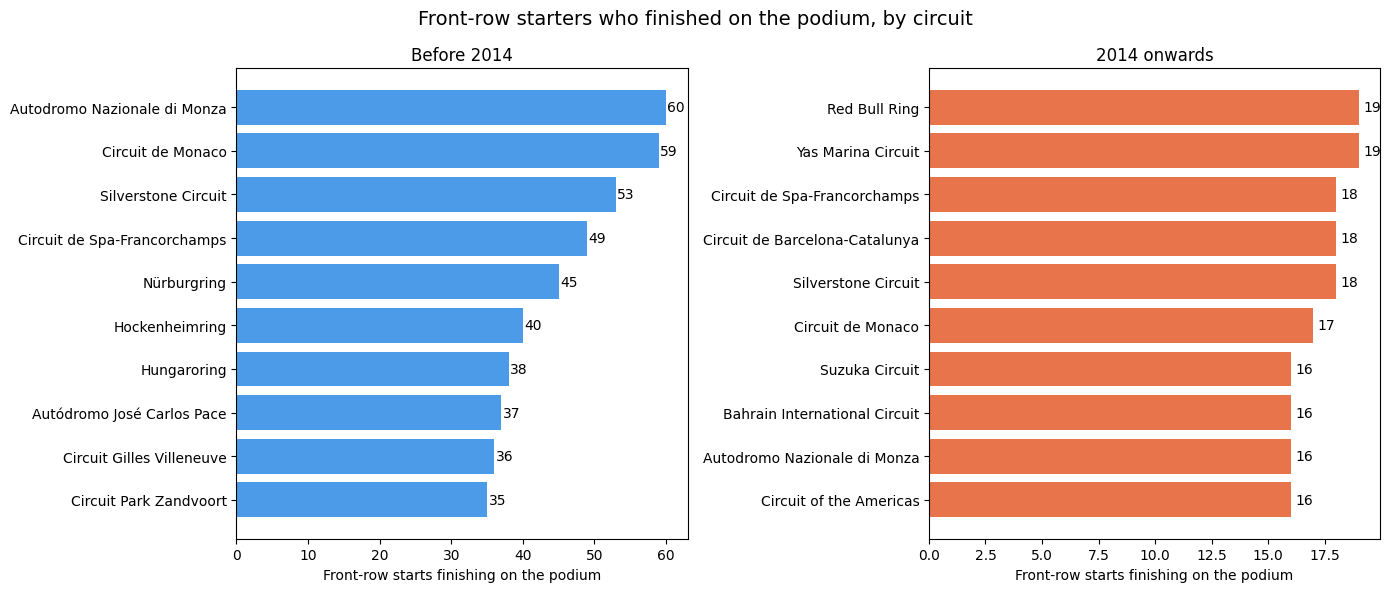

In [23]:
top = 10
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, df, title, color in [
    (axes[0], df_before_2014, 'Before 2014', '#4c9be8'),
    (axes[1], df_after_2014,  '2014 onwards', '#e8744c'),
]:
    data = df.head(top).sort_values('num')   # sort so the biggest bar ends up on top
    ax.barh(data['circuit'], data['num'], color=color)
    ax.set_title(title)
    ax.set_xlabel('Front-row starts finishing on the podium')
    for i, v in enumerate(data['num']):
        ax.text(v + 0.2, i, str(v), va='center')   # value labels

fig.suptitle('Front-row starters who finished on the podium, by circuit', fontsize=14)
plt.tight_layout()
plt.show()

## **Do drivers podium more often when racing at a circuit in their home country than elsewhere, after controlling for starting position (i.e., comparing drivers who started from similar grid positions, so the effect isn’t just because home drivers happen to qualify better)?**

In [24]:
nat_to_country = {
    'American': 'USA',
    'American-Italian': 'USA',
    'Argentine': 'Argentina',
    'Argentine-Italian': 'Argentina',
    'Argentinian': 'Argentina',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Brazilian': 'Brazil',
    'British': 'UK',
    'Canadian': 'Canada',
    'Chilean': 'Chile',
    'Chinese': 'China',
    'Colombian': 'Colombia',
    'Czech': 'Czech Republic',
    'Danish': 'Denmark',
    'Dutch': 'Netherlands',
    'East German': 'East Germany',
    'Finnish': 'Finland',
    'French': 'France',
    'German': 'Germany',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Indonesian': 'Indonesia',
    'Irish': 'Ireland',
    'Italian': 'Italy',
    'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein',
    'Malaysian': 'Malaysia',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand',
    'Polish': 'Poland',
    'Portuguese': 'Portugal',
    'Rhodesian': 'Zimbabwe',
    'Russian': 'Russia',
    'South African': 'South Africa',
    'Spanish': 'Spain',
    'Swedish': 'Sweden',
    'Swiss': 'Switzerland',
    'Thai': 'Thailand',
    'Uruguayan': 'Uruguay',
    'Venezuelan': 'Venezuela',
}


df = (
    cleaned_tables['results'][['raceId','position','grid','driverId']]
    .merge(cleaned_tables['races'][['raceId','circuitId']] , on='raceId')
    .merge(cleaned_tables['drivers'][['driverId','nationality']], on='driverId')
    .merge(cleaned_tables['circuits'][['circuitId','country']], on='circuitId')
)

df['driver_country'] = df['nationality'].map(nat_to_country)

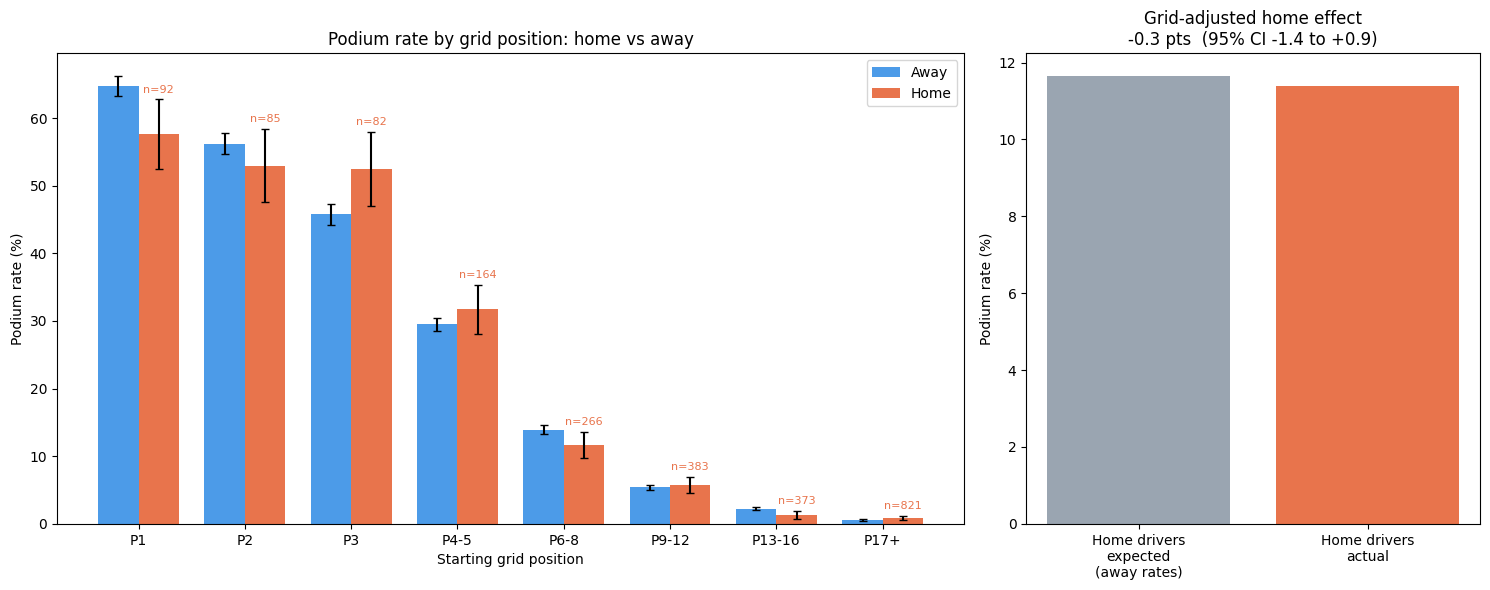

In [25]:
d = df.copy()
d = d[d['grid'] >= 1]                                  # drop pit-lane starts (grid == 0)
d['home']   = d['driver_country'] == d['country']
d['podium'] = (d['position'] <= 3)                     # NaN (DNF) -> False

bins   = [0, 1, 2, 3, 5, 8, 12, 16, 40]
labels = ['P1', 'P2', 'P3', 'P4-5', 'P6-8', 'P9-12', 'P13-16', 'P17+']
d['grid_bin'] = pd.cut(d['grid'], bins=bins, labels=labels)

# podium rate per grid bin, split by home/away
g = (d.groupby(['grid_bin', 'home'], observed=True)['podium']
       .agg(rate='mean', k='sum', n='size')
       .unstack('home'))

# standard error for error bars
def se(rate, n): return np.sqrt(rate * (1 - rate) / n)

# grid-adjusted effect: actual home podium rate vs the rate home drivers
# would have had if they converted like away drivers from the same grid bin
def adjusted_effect(data):
    t = data.groupby(['grid_bin', 'home'], observed=True)['podium'].agg(['mean', 'size']).unstack('home')
    t = t.dropna()
    w = t[('size', True)]
    expected = (t[('mean', False)] * w).sum() / w.sum()
    actual   = (t[('mean', True)]  * w).sum() / w.sum()
    return actual, expected

actual, expected = adjusted_effect(d)

# bootstrap CI for (actual - expected)
rng = np.random.default_rng(0)
boots = []
for _ in range(500):
    s = d.sample(len(d), replace=True, random_state=int(rng.integers(1e9)))
    a, e = adjusted_effect(s)
    boots.append(a - e)
lo, hi = np.percentile(boots, [2.5, 97.5])

# ---- plot ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [2, 1]})

x = np.arange(len(g))
wd = 0.38
away_rate, home_rate = g[('rate', False)] * 100, g[('rate', True)] * 100
away_err = se(g[('rate', False)], g[('n', False)]) * 100
home_err = se(g[('rate', True)],  g[('n', True)])  * 100

ax1.bar(x - wd/2, away_rate, wd, yerr=away_err, color='#4c9be8', label='Away', capsize=3)
ax1.bar(x + wd/2, home_rate, wd, yerr=home_err, color='#e8744c', label='Home', capsize=3)
for i, (_, r) in enumerate(g.iterrows()):
    ax1.text(i + wd/2, home_rate.iloc[i] + home_err.iloc[i] + 1, f"n={int(r[('n', True)])}",
             ha='center', fontsize=8, color='#e8744c')
ax1.set_xticks(x)
ax1.set_xticklabels(g.index)
ax1.set_xlabel('Starting grid position')
ax1.set_ylabel('Podium rate (%)')
ax1.set_title('Podium rate by grid position: home vs away')
ax1.legend()

ax2.bar(['Home drivers\nexpected\n(away rates)', 'Home drivers\nactual'],
        [expected * 100, actual * 100], color=['#9aa5b1', '#e8744c'])
ax2.set_ylabel('Podium rate (%)')
ax2.set_title(f'Grid-adjusted home effect\n{(actual-expected)*100:+.1f} pts  (95% CI {lo*100:+.1f} to {hi*100:+.1f})')

plt.tight_layout()
plt.show()

## **Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?**

In [26]:
df = cleaned_tables['results'][['raceId', 'statusId','constructorId']].merge(cleaned_tables['status'], on='statusId').merge(cleaned_tables['constructors'][['constructorId', 'name']], on='constructorId').merge(cleaned_tables['races'][['raceId', 'year']], on='raceId')

mechanical_failures = ['Engine', 'Gearbox', 'Hydraulics']

all_races_by_constructor = df[df['status'].isin(mechanical_failures)]

r_2014_2021 = all_races_by_constructor[all_races_by_constructor['year'].between(2014, 2021)]
r_2022_2024 = all_races_by_constructor[all_races_by_constructor['year'].between(2022, 2024)]

# r_2014_2021.groupby('name')

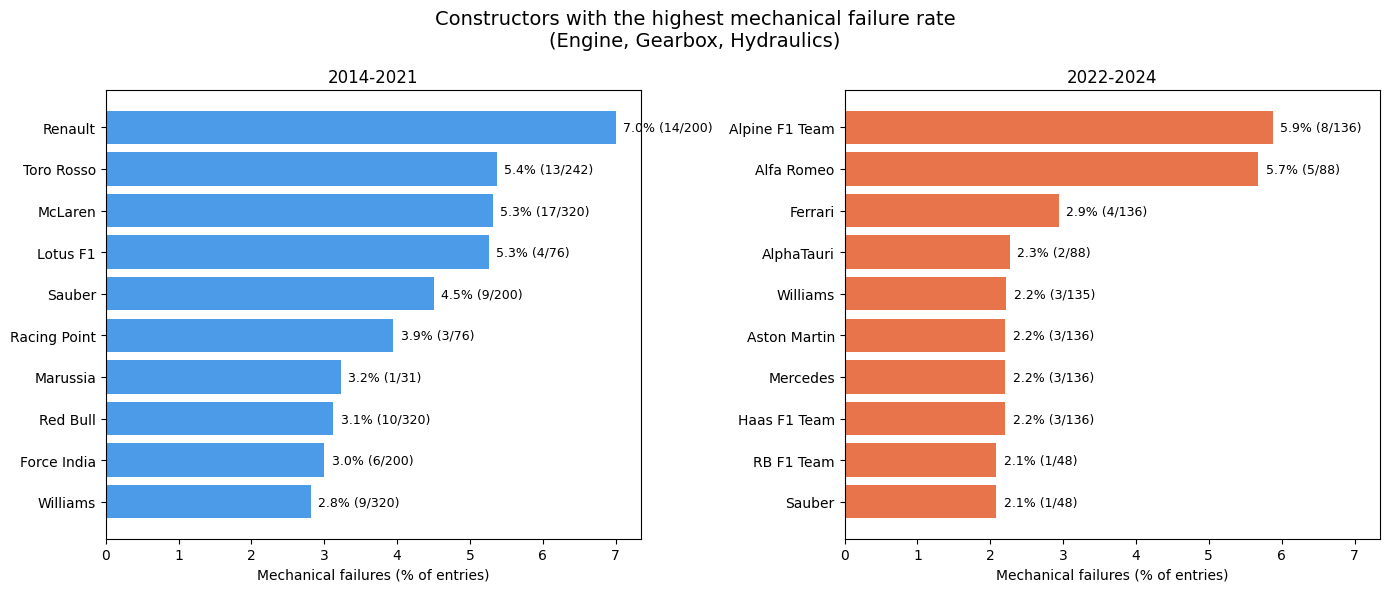

In [27]:
def failure_summary(df, start, end, min_entries=20):
    d = df[df['year'].between(start, end)]
    g = d.groupby('name').agg(
        entries=('raceId', 'size'),
        failures=('status', lambda s: s.isin(mechanical_failures).sum()),
    )
    g['rate'] = g['failures'] / g['entries'] * 100
    return g[g['entries'] >= min_entries]   # drop constructors with tiny samples

periods = [(2014, 2021, '#4c9be8'), (2022, 2024, '#e8744c')]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

for ax, (start, end, color) in zip(axes, periods):
    s = failure_summary(df, start, end).nlargest(10, 'rate').sort_values('rate')
    ax.barh(s.index, s['rate'], color=color)
    for i, (rate, n, f) in enumerate(zip(s['rate'], s['entries'], s['failures'])):
        ax.text(rate + 0.1, i, f'{rate:.1f}% ({f}/{n})', va='center', fontsize=9)
    ax.set_title(f'{start}-{end}')
    ax.set_xlabel('Mechanical failures (% of entries)')

fig.suptitle('Constructors with the highest mechanical failure rate\n(Engine, Gearbox, Hydraulics)', fontsize=14)
plt.tight_layout()
plt.show()

# **Feature Selection & Engineering**

In [28]:
def add_pre_race_driver_standings(modeling_data, driver_standings, races):
    """
    Add current-season pre-race points/wins and previous-season
    final points/wins for each driver.

    Current-season features use the latest standings record from
    an earlier round in the same season. If no earlier record
    exists, they default to zero.

    Previous-season features use the driver's final standings
    record from the immediately preceding season, or zero if
    unavailable.
    """

    race_order = races[['raceId', 'year', 'round']].copy()

    standings = (
        driver_standings[['raceId', 'driverId', 'points', 'wins']]
        .merge(
            race_order,
            on='raceId',
            how='left',
            validate='many_to_one'
        )
    )

    data = modeling_data.copy().reset_index(drop=True)
    data['_row_id'] = range(len(data))

    # Attach each driver's standings records from the same season.
    candidates = data[
        ['_row_id', 'driverId', 'year', 'round']
    ].merge(
        standings,
        on=['driverId', 'year'],
        how='left',
        suffixes=('', '_standing')
    )

    # Only records from earlier rounds are eligible.
    candidates = candidates[
        candidates['round_standing'] < candidates['round']
    ]

    # Latest standings record before the target race.
    current_season = (
        candidates
        .sort_values(
            ['_row_id', 'round_standing', 'raceId']
        )
        .drop_duplicates('_row_id', keep='last')
        [
            ['_row_id', 'points', 'wins']
        ]
        .rename(columns={
            'points': 'driver_points_before_race',
            'wins': 'driver_wins_before_race'
        })
    )

    data = data.merge(
        current_season,
        on='_row_id',
        how='left',
        validate='one_to_one',
        sort=False
    )

    data[
        ['driver_points_before_race', 'driver_wins_before_race']
    ] = data[
        ['driver_points_before_race', 'driver_wins_before_race']
    ].fillna(0)

    # Determine the final standings record for each driver/season.
    season_finals = (
        standings
        .sort_values(['driverId', 'year', 'round', 'raceId'])
        .drop_duplicates(['driverId', 'year'], keep='last')
        [['driverId', 'year', 'points', 'wins']]
        .rename(columns={
            'year': 'previous_season',
            'points': 'driver_previous_season_points',
            'wins': 'driver_previous_season_wins'
        })
    )

    # Match only the immediately preceding calendar season.
    data['previous_season'] = data['year'] - 1

    data = data.merge(
        season_finals,
        left_on=['driverId', 'previous_season'],
        right_on=['driverId', 'previous_season'],
        how='left',
        validate='many_to_one',
        sort=False
    )

    data[
        ['driver_previous_season_points', 'driver_previous_season_wins']
    ] = data[
        ['driver_previous_season_points', 'driver_previous_season_wins']
    ].fillna(0)

    return data.drop(columns=['_row_id', 'previous_season'])

In [29]:
def add_pre_race_constructor_standings(
    modeling_data, constructor_standings, races
):
    """
    Add current-season pre-race points/wins and previous-season
    final points/wins for each constructor.

    Current-season features use the latest standings record from
    a strictly earlier round in the same season. If none exists,
    they default to zero.

    Previous-season features use the final standings record from
    the immediately preceding calendar season, or zero if unavailable.
    """

    race_order = races[['raceId', 'year', 'round']].copy()

    standings = (
        constructor_standings[
            ['raceId', 'constructorId', 'points', 'wins']
        ]
        .merge(
            race_order,
            on='raceId',
            how='left',
            validate='many_to_one'
        )
        .rename(columns={
            'year': 'standing_year',
            'round': 'standing_round'
        })
    )

    data = modeling_data.copy().reset_index(drop=True)
    data['_row_id'] = range(len(data))

    # Match standings records for the same constructor and season.
    candidates = data[
        ['_row_id', 'constructorId', 'year', 'round']
    ].merge(
        standings,
        left_on=['constructorId', 'year'],
        right_on=['constructorId', 'standing_year'],
        how='left',
        validate='many_to_many'
    )

    # Only standings from strictly earlier rounds are eligible.
    candidates = candidates[
        candidates['standing_round'] < candidates['round']
    ]

    # Select the most recent eligible standings record.
    current_season = (
        candidates
        .sort_values(
            ['_row_id', 'standing_round', 'raceId']
        )
        .drop_duplicates('_row_id', keep='last')
        [
            ['_row_id', 'points', 'wins']
        ]
        .rename(columns={
            'points': 'constructor_points_before_race',
            'wins': 'constructor_wins_before_race'
        })
    )

    data = data.merge(
        current_season,
        on='_row_id',
        how='left',
        validate='one_to_one',
        sort=False
    )

    current_cols = [
        'constructor_points_before_race',
        'constructor_wins_before_race'
    ]
    data[current_cols] = data[current_cols].fillna(0)

    # Select each constructor's final standings record per season.
    season_finals = (
        standings
        .sort_values(
            ['constructorId', 'standing_year', 'standing_round', 'raceId']
        )
        .drop_duplicates(
            ['constructorId', 'standing_year'],
            keep='last'
        )
        [
            ['constructorId', 'standing_year', 'points', 'wins']
        ]
        .rename(columns={
            'standing_year': 'previous_season',
            'points': 'constructor_previous_season_points',
            'wins': 'constructor_previous_season_wins'
        })
    )

    data['previous_season'] = data['year'] - 1

    data = data.merge(
        season_finals,
        on=['constructorId', 'previous_season'],
        how='left',
        validate='many_to_one',
        sort=False
    )

    previous_cols = [
        'constructor_previous_season_points',
        'constructor_previous_season_wins'
    ]
    data[previous_cols] = data[previous_cols].fillna(0)

    return data.drop(columns=['_row_id', 'previous_season'])

In [30]:
def add_pit_stop_features(modeling_data, results, pit_stops, races):
    """
    Add pre-race pit-stop history features.

    Current-season features use covered races earlier in the same season.
    If no eligible earlier covered races exist, current-season metrics
    default to zero.

    Previous-season features use covered races in the previous calendar
    year. If no eligible history exists, values remain NaN.

    Races without any pit-stop records are excluded from the averages.
    Within covered races, participating drivers without stop records
    are treated as having zero stops.
    """

    race_info = races[['raceId', 'year', 'round']].copy()

    # Identify races with at least one pit-stop record.
    covered_races = pit_stops['raceId'].dropna().unique()

    # Convert durations to numeric seconds where possible.
    stops = pit_stops[['raceId', 'driverId', 'duration']].copy()
    stops['duration_seconds'] = pd.to_numeric(
        stops['duration'], errors='coerce'
    )

    # Summarize each driver's stops within each race.
    race_stop_stats = (
        stops.groupby(['raceId', 'driverId'], as_index=False)
        .agg(
            stops_in_race=('raceId', 'size'),
            mean_stop_duration=('duration_seconds', 'mean')
        )
    )

    # Driver participation in covered races only.
    participation = (
        results[['raceId', 'driverId']]
        .drop_duplicates()
        .merge(
            race_info,
            on='raceId',
            how='left',
            validate='many_to_one'
        )
    )

    participation = participation[
        participation['raceId'].isin(covered_races)
    ].copy()

    # Assume no recorded stops means zero stops within a covered race.
    participation = participation.merge(
        race_stop_stats,
        on=['raceId', 'driverId'],
        how='left',
        validate='one_to_one'
    )

    participation['stops_in_race'] = (
        participation['stops_in_race'].fillna(0)
    )

    # Preserve input row order and index-independent row identity.
    data = modeling_data.copy().reset_index(drop=True)
    data['_row_id'] = range(len(data))

    # Current-season features: only races strictly before target round.
    current_candidates = data[
        ['_row_id', 'driverId', 'year', 'round']
    ].merge(
        participation,
        on=['driverId', 'year'],
        how='left',
        suffixes=('', '_history')
    )

    current_candidates = current_candidates[
        current_candidates['round_history'].lt(
            current_candidates['round']
        )
    ]

    current_features = (
        current_candidates.groupby('_row_id')
        .agg(
            avg_stop_duration_before_race=(
                'mean_stop_duration', 'mean'
            ),
            avg_stops_per_race_before_race=(
                'stops_in_race', 'mean'
            )
        )
        .reset_index()
    )

    data = data.merge(
        current_features,
        on='_row_id',
        how='left',
        validate='one_to_one',
        sort=False
    )

    # No eligible earlier covered races => current-season defaults of zero.
    current_cols = [
        'avg_stop_duration_before_race',
        'avg_stops_per_race_before_race'
    ]
    data[current_cols] = data[current_cols].fillna(0)

    # Previous-season features: aggregate the previous calendar year.
    previous_features = (
        participation
        .groupby(['driverId', 'year'])
        .agg(
            avg_stop_duration_previous_season=(
                'mean_stop_duration', 'mean'
            ),
            avg_stops_per_race_previous_season=(
                'stops_in_race', 'mean'
            )
        )
        .reset_index()
        .rename(columns={'year': 'previous_season'})
    )

    data['previous_season'] = data['year'] - 1

    data = data.merge(
        previous_features,
        on=['driverId', 'previous_season'],
        how='left',
        validate='many_to_one',
        sort=False
    )

    updated_cols = [
        'avg_stop_duration_previous_season',
        'avg_stops_per_race_previous_season'
    ]
    data[updated_cols] = data[updated_cols].fillna(0)

    # No previous-season match remains NaN; do not fill it with zero.
    return data.drop(columns=['_row_id', 'previous_season'])

In [31]:
def add_driver_age(modeling_data):
    """
    Add driver age in years at the date of each target race.
    """

    data = modeling_data.copy()

    dob = pd.to_datetime(data['dob'], errors='coerce')
    race_date = pd.to_datetime(data['date'], errors='coerce')

    data['age'] = (
        (race_date - dob).dt.days / 365.2425
    )

    # Invalid dates or dates before birth are not valid ages.
    invalid_age = (data['age'] < 0) | dob.isna() | race_date.isna()
    data.loc[invalid_age, 'age'] = float('nan')
    data['age'] = data['age'].astype(int)

    return data


## **Final Feature Selection**

In [32]:
print(cleaned_tables['races'].merge(cleaned_tables['qualifying'], on= 'raceId')['year'].min())

1994


### **Mostly Null Variant**

In [33]:
modeling_data = (
    cleaned_tables['results'][['driverId', 'constructorId', 'raceId', 'grid', 'positionOrder']]
    .merge(cleaned_tables['races'][['circuitId', 'raceId', 'year', 'date', 'time', 'round']], on='raceId', how= 'left')
    .merge(cleaned_tables['circuits'][['circuitId', 'country', 'circuitRef', 'alt']], on = 'circuitId', how= 'left')
    .merge(cleaned_tables['qualifying'][['driverId', 'raceId', 'q1', 'q2', 'q3', 'position']], on= ['raceId', 'driverId'], how= 'left')
    .merge(cleaned_tables['drivers'][['driverId', 'dob', 'nationality']], on='driverId', how= 'left')
    .merge(cleaned_tables['constructors'][['constructorId', 'constructorRef', 'nationality']], on= 'constructorId', how= 'left', suffixes=('_driver', '_constructor'))
)

In [34]:
# Modeling Data is now the variant with a large number of nulls in key columns like q1 and position
modeling_data = add_pre_race_driver_standings(
    modeling_data=modeling_data,
    driver_standings=cleaned_tables['driver_standings'],
    races=cleaned_tables['races']
)

modeling_data = add_pre_race_constructor_standings(
    modeling_data=modeling_data,
    constructor_standings=cleaned_tables['constructor_standings'],
    races=cleaned_tables['races']
)

modeling_data = add_driver_age(modeling_data)

modeling_data = add_pit_stop_features(
    modeling_data=modeling_data,
    results=cleaned_tables['results'],
    pit_stops=cleaned_tables['pit_stops'],
    races=cleaned_tables['races']
)

# Fallback to grid when position is missing in early years
modeling_data['position'] = modeling_data['position'].fillna(modeling_data['grid'])

modeling_data = modeling_data.drop(columns=['time', 'circuitId', 'raceId', 'driverId', 'constructorId', 'circuitRef', 'constructorRef', 'dob', 'date'])

modeling_data.info()
modeling_data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26531 entries, 0 to 26530
Data columns (total 25 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   grid                                26531 non-null  int64  
 1   positionOrder                       26531 non-null  int64  
 2   year                                26531 non-null  int64  
 3   round                               26531 non-null  int64  
 4   country                             26531 non-null  object 
 5   alt                                 26531 non-null  int64  
 6   q1                                  10338 non-null  float64
 7   q2                                  5847 non-null   float64
 8   q3                                  3629 non-null   float64
 9   position                            26531 non-null  float64
 10  nationality_driver                  26531 non-null  object 
 11  nationality_constructor             26531

,grid,positionOrder,year,round,country,alt,q1,q2,q3,position,...,driver_previous_season_wins,constructor_points_before_race,constructor_wins_before_race,constructor_previous_season_points,constructor_previous_season_wins,age,avg_stop_duration_before_race,avg_stops_per_race_before_race,avg_stop_duration_previous_season,avg_stops_per_race_previous_season
0,1,1,2008,1,Australia,10,86.572,85.187,86.714,1.0,...,4.0,0.0,0.0,218.0,8.0,23,0.0,0.0,0.0,0.0
1,5,2,2008,1,Australia,10,85.960,85.518,87.236,5.0,...,0.0,0.0,0.0,101.0,0.0,30,0.0,0.0,0.0,0.0
2,7,3,2008,1,Australia,10,86.295,86.059,88.687,7.0,...,0.0,0.0,0.0,33.0,0.0,22,0.0,0.0,0.0,0.0
3,11,4,2008,1,Australia,10,86.907,86.188,NaN,12.0,...,4.0,0.0,0.0,51.0,0.0,26,0.0,0.0,0.0,0.0
4,3,5,2008,1,Australia,10,85.664,85.452,87.079,3.0,...,0.0,0.0,0.0,218.0,8.0,26,0.0,0.0,0.0,0.0


### **Drop Columns Q1, Q2, Q3 Variant**

In [35]:
dropped_qual_time_columns = modeling_data.copy()

dropped_qual_time_columns = dropped_qual_time_columns.drop(columns= ['q1', 'q2', 'q3'])

dropped_qual_time_columns.info()
dropped_qual_time_columns .head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26531 entries, 0 to 26530
Data columns (total 22 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   grid                                26531 non-null  int64  
 1   positionOrder                       26531 non-null  int64  
 2   year                                26531 non-null  int64  
 3   round                               26531 non-null  int64  
 4   country                             26531 non-null  object 
 5   alt                                 26531 non-null  int64  
 6   position                            26531 non-null  float64
 7   nationality_driver                  26531 non-null  object 
 8   nationality_constructor             26531 non-null  object 
 9   driver_points_before_race           26531 non-null  float64
 10  driver_wins_before_race             26531 non-null  float64
 11  driver_previous_season_points       26531

,grid,positionOrder,year,round,country,alt,position,nationality_driver,nationality_constructor,driver_points_before_race,...,driver_previous_season_wins,constructor_points_before_race,constructor_wins_before_race,constructor_previous_season_points,constructor_previous_season_wins,age,avg_stop_duration_before_race,avg_stops_per_race_before_race,avg_stop_duration_previous_season,avg_stops_per_race_previous_season
0,1,1,2008,1,Australia,10,1.0,British,British,0.0,...,4.0,0.0,0.0,218.0,8.0,23,0.0,0.0,0.0,0.0
1,5,2,2008,1,Australia,10,5.0,German,German,0.0,...,0.0,0.0,0.0,101.0,0.0,30,0.0,0.0,0.0,0.0
2,7,3,2008,1,Australia,10,7.0,German,British,0.0,...,0.0,0.0,0.0,33.0,0.0,22,0.0,0.0,0.0,0.0
3,11,4,2008,1,Australia,10,12.0,Spanish,French,0.0,...,4.0,0.0,0.0,51.0,0.0,26,0.0,0.0,0.0,0.0
4,3,5,2008,1,Australia,10,3.0,Finnish,British,0.0,...,0.0,0.0,0.0,218.0,8.0,26,0.0,0.0,0.0,0.0


### **Drop Rows Q1 Dropped Columns Q2, Q3 Variant**

In [36]:
dropped_qual_time_rows = modeling_data.copy()

dropped_qual_time_rows = dropped_qual_time_rows.drop(columns= ['q2', 'q3'])

dropped_qual_time_rows = dropped_qual_time_rows[dropped_qual_time_rows['q1'].isnull() == False]

dropped_qual_time_rows.info()
dropped_qual_time_rows.head()

<class 'pandas.core.frame.DataFrame'>
Index: 10338 entries, 0 to 26530
Data columns (total 23 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   grid                                10338 non-null  int64  
 1   positionOrder                       10338 non-null  int64  
 2   year                                10338 non-null  int64  
 3   round                               10338 non-null  int64  
 4   country                             10338 non-null  object 
 5   alt                                 10338 non-null  int64  
 6   q1                                  10338 non-null  float64
 7   position                            10338 non-null  float64
 8   nationality_driver                  10338 non-null  object 
 9   nationality_constructor             10338 non-null  object 
 10  driver_points_before_race           10338 non-null  float64
 11  driver_wins_before_race             10338 non-

,grid,positionOrder,year,round,country,alt,q1,position,nationality_driver,nationality_constructor,...,driver_previous_season_wins,constructor_points_before_race,constructor_wins_before_race,constructor_previous_season_points,constructor_previous_season_wins,age,avg_stop_duration_before_race,avg_stops_per_race_before_race,avg_stop_duration_previous_season,avg_stops_per_race_previous_season
0,1,1,2008,1,Australia,10,86.572,1.0,British,British,...,4.0,0.0,0.0,218.0,8.0,23,0.0,0.0,0.0,0.0
1,5,2,2008,1,Australia,10,85.960,5.0,German,German,...,0.0,0.0,0.0,101.0,0.0,30,0.0,0.0,0.0,0.0
2,7,3,2008,1,Australia,10,86.295,7.0,German,British,...,0.0,0.0,0.0,33.0,0.0,22,0.0,0.0,0.0,0.0
3,11,4,2008,1,Australia,10,86.907,12.0,Spanish,French,...,4.0,0.0,0.0,51.0,0.0,26,0.0,0.0,0.0,0.0
4,3,5,2008,1,Australia,10,85.664,3.0,Finnish,British,...,0.0,0.0,0.0,218.0,8.0,26,0.0,0.0,0.0,0.0


# **Predictive Modeling Task**

## **Old Implementation**

In [37]:
# print("########## Modeling Data Pre Classification ##########")

# imputing_all_qual_modeling_data.info()
# display(imputing_all_qual_modeling_data.head())
# modeling_data_backup = imputing_all_qual_modeling_data.copy()

# print("########## Modeling Data Post Classification ##########")

# imputing_all_qual_modeling_data['podium'] = imputing_all_qual_modeling_data['positionOrder'].isin([1, 2, 3]).astype(int)
# imputing_all_qual_modeling_data.info()
# display(imputing_all_qual_modeling_data.head())

# data = imputing_all_qual_modeling_data.copy()

# def create_modeling_split(data):
#     training = data[data['year'] <= 2019].copy()
#     validation = data[data['year'].between(2020, 2021)].copy()
#     testing = data[data['year'] >= 2022].copy()

#     training = training[data.columns]
#     validation = validation[data.columns]
#     testing = testing[data.columns]

#     print("Training:", training.shape)
#     print("Validation:", validation.shape)
#     print("Testing:", testing.shape)

#     training_percentage = (len(training)/len(data)) * 100
#     validation_percentage = (len(validation)/len(data)) * 100
#     testing_percentage = (len(testing)/len(data)) * 100

#     print("Training Percentage of Data:", training_percentage)
#     print("Validation Percentage of Data:", validation_percentage)
#     print("Testing Percentage of Data:", testing_percentage)

#     return training, validation, testing

# training, validation, testing = create_modeling_split(data)

In [38]:
# numeric_features = ['grid', 'round', 'year', 'lng', 'lat', 'alt', 
#                     'driver_points_before_race', 'driver_wins_before_race', 'driver_previous_season_points', 'driver_previous_season_wins', 
#                     'age', 'q1', 'q2', 'q3']

# categorical_features = ['country', 'circuitRef', 'constructorRef', 'nationality', 'driverRef']

# features = numeric_features + categorical_features

# x_train = training[features]
# y_train = training['podium']

# x_val = validation[features]
# y_val = validation['podium']

# x_test = testing[features]
# y_test = testing['podium']

# display(x_train.head())
# display(y_train.head())

# numeric_transformer = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('scaler', StandardScaler())
# ])

# categorical_transformer = Pipeline([
#     ('imputer', SimpleImputer(strategy='most_frequent')),
#     ('encoder', OneHotEncoder(
#         handle_unknown='ignore',
#         sparse_output=False
#     ))
# ])

# preprocessor = ColumnTransformer([
#     ('num', numeric_transformer, numeric_features),
#     ('cat', categorical_transformer, categorical_features)
# ])

# x_train = preprocessor.fit_transform(x_train)
# x_val = preprocessor.transform(x_val)
# x_test = preprocessor.transform(x_test)

# logistic_model = LogisticRegression(max_iter=1000)

# rf_model = RandomForestClassifier(
#     n_estimators=100,
#     random_state=42
# )

# logistic_model.fit(x_train, y_train)
# rf_model.fit(x_train, y_train)

In [39]:
# y_pred_rf = rf_model.predict(x_test)
# print("Random Forest Test Accuracy:", accuracy_score(y_test, y_pred_rf))

# print('\n')

# y_pred_lm = logistic_model.predict(x_test)
# print("Logistic Accuracy:", accuracy_score(y_test, y_pred_lm))
# print("Logistic Precision:", precision_score(y_test, y_pred_lm))
# print("Recall:", recall_score(y_test, y_pred_lm))
# print("F1 Score:", f1_score(y_test, y_pred_lm))
# print("\nClassification Report:")
# print(classification_report(y_test, y_pred_lm))
# print("\nConfusion Matrix:")
# print(confusion_matrix(y_test, y_pred_lm))

# cm = confusion_matrix(y_test, y_pred_lm)
# sns.heatmap(cm, annot=True, fmt="d", cmap='Blues')
# plt.xlabel('Predicted')
# plt.ylabel('Actual')
# plt.title('Confusion Matrix')
# plt.show()

In [40]:
# y_prob_rf = rf_model.predict_proba(x_test)[:, 1]

# roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
# pr_auc_rf = average_precision_score(y_test, y_prob_rf)

# print("##### Random Forest #####")
# print("Random Forest ROC-AUC:", roc_auc_rf)
# print("Random Forest PR-AUC:", pr_auc_rf)
# print("Random Forest F1 Score:", f1_score(y_test, y_pred_rf))

# print("\n")
# print("##### Logistic Regression #####")
# y_prob_lm = logistic_model.predict_proba(x_test)[:, 1]

# roc_auc_lm = roc_auc_score(y_test, y_prob_lm)
# pr_auc_lm = average_precision_score(y_test, y_prob_lm)

# print("Logistic Regression ROC-AUC:", roc_auc_lm)
# print("Logistic Regression PR-AUC:", pr_auc_lm)
# print("Logistic Regression F1 Score:", f1_score(y_test, y_pred_lm))


In [41]:
# np.random.seed(42)
# tf.random.set_seed(42)

# scaler = StandardScaler()
# x_train_scaled = x_train
# x_val_scaled = x_val
# x_test_scaled = x_test
# print(f"Train: {x_train.shape}, Test: {x_test.shape}")

# early_stop = EarlyStopping(monitor='val_loss', mode = 'min', patience=8,
# restore_best_weights=True)

# def build_model(input_dims):
#     model = keras.Sequential([
#         layers.Input(shape=(input_dims.shape[1],)),

#         layers.Dense(
#             32,
#             activation='relu',
#             kernel_regularizer=keras.regularizers.l2(1e-4)
#         ),
#         layers.Dropout(0.3),

#         layers.Dense(
#             16,
#             activation='relu',
#             kernel_regularizer=keras.regularizers.l2(1e-4)
#         ),
#         layers.Dropout(0.2),

#         layers.Dense(1, activation='sigmoid')
#     ])

#     model.compile(
#         optimizer='adam',
#         loss='binary_crossentropy',
#         metrics=[
#             'accuracy',
#             keras.metrics.AUC(name='roc_auc'),
#             keras.metrics.AUC(curve='PR', name='pr_auc')
#         ]
#     )

#     return model

# neural_model = build_model(x_train)
# history_nm = neural_model.fit(
#     x_train_scaled,
#     y_train,
#     validation_data=(x_val_scaled, y_val),
#     epochs=200,
#     batch_size=32,
#     verbose=1,
#     callbacks=[early_stop] )

In [42]:
# plt.figure(figsize=(14, 5))

# # Accuracy
# plt.subplot(1, 2, 1)
# plt.plot(history_nm.history['accuracy'], label='Training Accuracy')
# plt.plot(history_nm.history['val_accuracy'], label='Validation Accuracy')
# plt.xlabel('Epoch')
# plt.ylabel('Accuracy')
# plt.title('Neural Network Accuracy')
# plt.legend()
# plt.grid(True)

# # Loss
# plt.subplot(1, 2, 2)
# plt.plot(history_nm.history['loss'], label='Training Loss')
# plt.plot(history_nm.history['val_loss'], label='Validation Loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.title('Neural Network Loss')
# plt.legend()
# plt.grid(True)

# plt.tight_layout()
# plt.show()

# y_prob_nn = neural_model.predict(x_test_scaled).ravel()
# y_pred_nn = (y_prob_nn >= 0.5).astype(int)

# # Metrics
# accuracy = accuracy_score(y_test, y_pred_nn)
# precision = precision_score(y_test, y_pred_nn, zero_division=0)
# recall = recall_score(y_test, y_pred_nn, zero_division=0)
# f1 = f1_score(y_test, y_pred_nn, zero_division=0)
# roc_auc = roc_auc_score(y_test, y_prob_nn)
# pr_auc = average_precision_score(y_test, y_prob_nn)

# print("===== Neural Network Test Results =====")
# print(f"Accuracy:  {accuracy:.4f}")
# print(f"Precision: {precision:.4f}")
# print(f"Recall:    {recall:.4f}")
# print(f"F1 Score:  {f1:.4f}")
# print(f"ROC-AUC:   {roc_auc:.4f}")
# print(f"PR-AUC:    {pr_auc:.4f}")

# print("\nClassification Report:")
# print(classification_report(y_test, y_pred_nn, zero_division=0))

# # Confusion matrix
# cm = confusion_matrix(y_test, y_pred_nn)

# plt.figure(figsize=(6, 5))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
# plt.xlabel('Predicted')
# plt.ylabel('Actual')
# plt.title('Neural Network — Test Confusion Matrix')
# plt.tight_layout()
# plt.show()

# metrics = {
#     'Accuracy': accuracy,
#     'Precision': precision,
#     'Recall': recall,
#     'F1 Score': f1,
#     'ROC-AUC': roc_auc,
#     'PR-AUC (AP)': pr_auc
# }

# plt.figure(figsize=(10, 5))
# bars = plt.bar(metrics.keys(), metrics.values())

# plt.ylim(0, 1)
# plt.ylabel('Score')
# plt.title('Neural Network — Test Metrics')
# plt.xticks(rotation=25, ha='right')

# for bar, score in zip(bars, metrics.values()):
#     plt.text(
#         bar.get_x() + bar.get_width() / 2,
#         bar.get_height() + 0.015,
#         f'{score:.3f}',
#         ha='center'
#     )

# plt.tight_layout()
# plt.show()

## **Statstical Models**

In [43]:
categorical_cols = ['country', 'circuitRef', 'driverRef', 'nationality_driver', 'nationality_constructor', 'constructorRef']
numeric_cols = ['year', 'round', 'lng', 'lat', 'alt', 'grid', 'q1', 'q2', 'q3', 'position', 
                     'driver_points_before_race', 'driver_wins_before_race', 'driver_previous_season_points',
                     'driver_previous_season_wins', 'age', 'avg_stop_duration_before_race', 'avg_stops_per_race_before_race'
                     'avg_stop_duration_previous_season', 'avg_stops_per_race_previous_season',
                     'constructor_points_before_race', 'constructor_wins_before_race', 'constructor_previous_season_points',
                     'constructor_previous_season_wins'
                    ]

In [44]:
datasets = [
    (dropped_qual_time_columns, numeric_cols, categorical_cols, 'Drop Qualification Time Columns'),
    (dropped_qual_time_rows, numeric_cols, categorical_cols, 'Drop Qualification Time 1 Rows'),
]

### **Generic Logistic Regression**

In [45]:
def train_logistic_regression_model(input_data, numeric_cols, categorical_cols, ax, title):
    from sklearn.metrics import (
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        roc_auc_score,
        precision_recall_curve
    )

    input_data = input_data.copy()
    input_data['podium'] = input_data['positionOrder'].isin([1, 2, 3]).astype(int)

    training = input_data[input_data['year'] <= 2019].copy()
    validation = input_data[input_data['year'].between(2020, 2021)].copy()
    testing = input_data[input_data['year'] >= 2022].copy()

    excluded = {'positionOrder', 'podium', 'year'}

    numeric_features = [
        col for col in numeric_cols
        if col in input_data.columns and col not in excluded
    ]
    categorical_features = [
        col for col in categorical_cols
        if col in input_data.columns and col not in excluded
    ]

    features = numeric_features + categorical_features

    x_train = training[features]
    y_train = training['podium']

    x_val = validation[features]
    y_val = validation['podium']

    x_test = testing[features]
    y_test = testing['podium']

    numeric_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ])

    transformers = []

    if numeric_features:
        transformers.append(
            ('numerical', numeric_transformer, numeric_features)
        )

    if categorical_features:
        transformers.append(
            ('categorical', categorical_transformer, categorical_features)
        )

    preprocessor = ColumnTransformer(transformers)

    x_train = preprocessor.fit_transform(x_train)
    x_val = preprocessor.transform(x_val)
    x_test = preprocessor.transform(x_test)

    logistic_model = LogisticRegression(max_iter=1000)
    logistic_model.fit(x_train, y_train)

    # Select the decision threshold using validation F1.
    y_val_prob = logistic_model.predict_proba(x_val)[:, 1]

    if y_val.nunique() == 2:
        precision, recall, thresholds = precision_recall_curve(
            y_val, y_val_prob
        )

        # The final precision/recall entries have no corresponding threshold.
        val_f1 = (
            2 * precision[:-1] * recall[:-1]
            / (precision[:-1] + recall[:-1] + 1e-12)
        )

        best_idx = np.argmax(val_f1)
        threshold = thresholds[best_idx]
    else:
        # F1-based threshold selection requires both classes in validation.
        threshold = 0.5

    # Evaluate once on the held-out test set.
    y_test_prob = logistic_model.predict_proba(x_val)[:, 1]
    y_pred = (y_test_prob >= threshold).astype(int)

    metrics = {
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1': f1_score(y_val, y_pred, zero_division=0),
        'ROC-AUC': (
            roc_auc_score(y_val, y_test_prob)
            if y_test.nunique() == 2
            else np.nan
        ),
        'PR-AUC': (
            average_precision_score(y_val, y_test_prob)
            if y_test.nunique() == 2 else np.nan
        )
    }

    ax.bar(metrics.keys(), metrics.values(), color='steelblue')
    ax.set_title(f'{title} (threshold={threshold:.3f})')
    ax.set_ylabel('Score')
    ax.set_ylim(0, 1.12)
    ax.tick_params(axis='x', rotation=20)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

    for i, value in enumerate(metrics.values()):
        if not np.isnan(value):
            ax.text(
                i, value + 0.02,
                f'{value:.3f}',
                ha='center',
                va='bottom',
                fontsize=9
            )

    return logistic_model, metrics

### **Generic Random Forest**

In [46]:
def train_random_forest_model(input_data, numeric_cols, categorical_cols, ax, title):
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import (
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        roc_auc_score,
        average_precision_score,
        precision_recall_curve
    )

    input_data = input_data.copy()
    input_data['podium'] = input_data['positionOrder'].isin([1, 2, 3]).astype(int)

    training = input_data[input_data['year'] <= 2019].copy()
    validation = input_data[input_data['year'].between(2020, 2021)].copy()
    testing = input_data[input_data['year'] >= 2022].copy()

    excluded = {'positionOrder', 'podium', 'year'}

    numeric_features = [
        col for col in numeric_cols
        if col in input_data.columns and col not in excluded
    ]
    categorical_features = [
        col for col in categorical_cols
        if col in input_data.columns and col not in excluded
    ]

    features = numeric_features + categorical_features

    x_train, y_train = training[features], training['podium']
    x_val, y_val = validation[features], validation['podium']
    x_test, y_test = testing[features], testing['podium']

    numeric_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median'))
    ])

    categorical_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ])

    transformers = []

    if numeric_features:
        transformers.append(
            ('numerical', numeric_transformer, numeric_features)
        )

    if categorical_features:
        transformers.append(
            ('categorical', categorical_transformer, categorical_features)
        )

    preprocessor = ColumnTransformer(transformers)

    x_train = preprocessor.fit_transform(x_train)
    x_val = preprocessor.transform(x_val)
    x_test = preprocessor.transform(x_test)

    # A small, predefined hyperparameter search.
    param_combinations = [
        {'n_estimators': 200, 'max_depth': 8, 'min_samples_leaf': 1},
        {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 1},
        {'n_estimators': 300, 'max_depth': 8, 'min_samples_leaf': 3},
        {'n_estimators': 300, 'max_depth': 12, 'min_samples_leaf': 3}
    ]

    best_model = None
    best_params = None
    best_threshold = 0.5
    best_val_f1 = -1

    for params in param_combinations:
        model = RandomForestClassifier(
            **params,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        )

        model.fit(x_train, y_train)

        val_prob = model.predict_proba(x_val)[:, 1]

        # Choose the decision threshold using validation F1.
        if y_val.nunique() == 2:
            precision, recall, thresholds = precision_recall_curve(
                y_val, val_prob
            )

            val_f1_scores = (
                2 * precision[:-1] * recall[:-1]
                / (precision[:-1] + recall[:-1] + 1e-12)
            )

            idx = np.argmax(val_f1_scores)
            threshold = thresholds[idx]
            val_f1 = val_f1_scores[idx]
        else:
            threshold = 0.5
            val_pred = (val_prob >= threshold).astype(int)
            val_f1 = f1_score(y_val, val_pred, zero_division=0)

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_model = model
            best_params = params.copy()
            best_threshold = threshold

    # Evaluate only the selected model on the held-out test set.
    y_test_prob = best_model.predict_proba(x_val)[:, 1]
    y_pred = (y_test_prob >= best_threshold).astype(int)

    metrics = {
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred, zero_division=0),
        'Recall': recall_score(y_val, y_pred, zero_division=0),
        'F1': f1_score(y_val, y_pred, zero_division=0),
        'ROC-AUC': (
            roc_auc_score(y_val, y_test_prob)
            if y_test.nunique() == 2 else np.nan
        ),
        'PR-AUC': (
            average_precision_score(y_val, y_test_prob)
            if y_test.nunique() == 2 else np.nan
        )
    }

    # Plot the selected model's test metrics.
    metric_names = list(metrics.keys())
    metric_values = list(metrics.values())

    ax.bar(metric_names, metric_values, color='forestgreen')
    ax.set_title(
        f'{title} | Random Forest\n'
        f'Params: {best_params} | '
        f'Threshold: {best_threshold:.3f} | '
        f'Validation F1: {best_val_f1:.3f}'
    )
    ax.set_ylabel('Score')
    ax.set_ylim(0, 1.12)
    ax.tick_params(axis='x', rotation=20)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

    for i, value in enumerate(metric_values):
        if not np.isnan(value):
            ax.text(
                i, value + 0.02,
                f'{value:.3f}',
                ha='center',
                va='bottom',
                fontsize=9
            )

    return {
        'metrics': metrics,
        'best_params': best_params,
        'best_threshold': best_threshold,
        'validation_f1': best_val_f1,
        'model': best_model,
        'preprocessor': preprocessor
    }

### **Results**

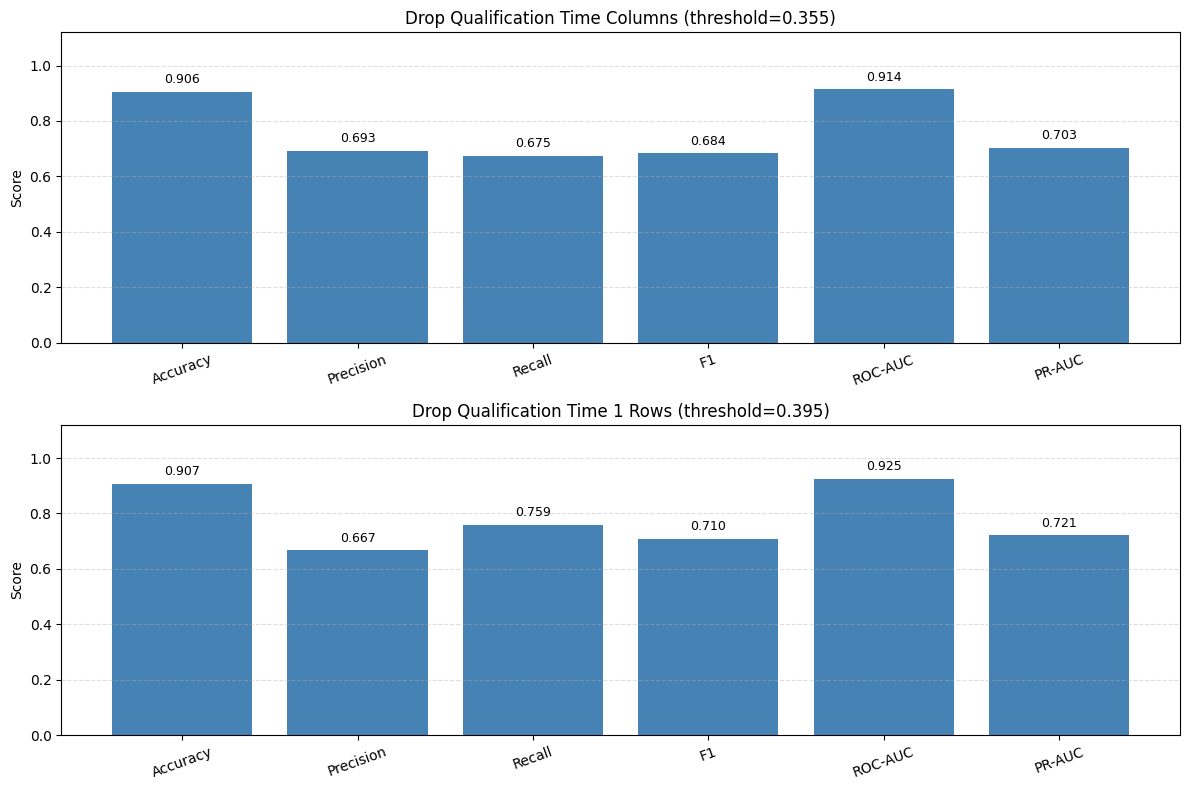

In [47]:
fig, axes = plt.subplots(
    nrows=len(datasets),
    ncols=1,
    figsize=(12, 4 * len(datasets))
)

axes = np.atleast_1d(axes)
all_metrics = {}

all_logistic_models = []

for i, (data, num_cols, cat_cols, title) in enumerate(datasets):
    model, all_metrics[title] = train_logistic_regression_model(
        data, num_cols, cat_cols,
        ax=axes[i],
        title=title
    )

    all_logistic_models.append(model)

fig.tight_layout()
plt.show()

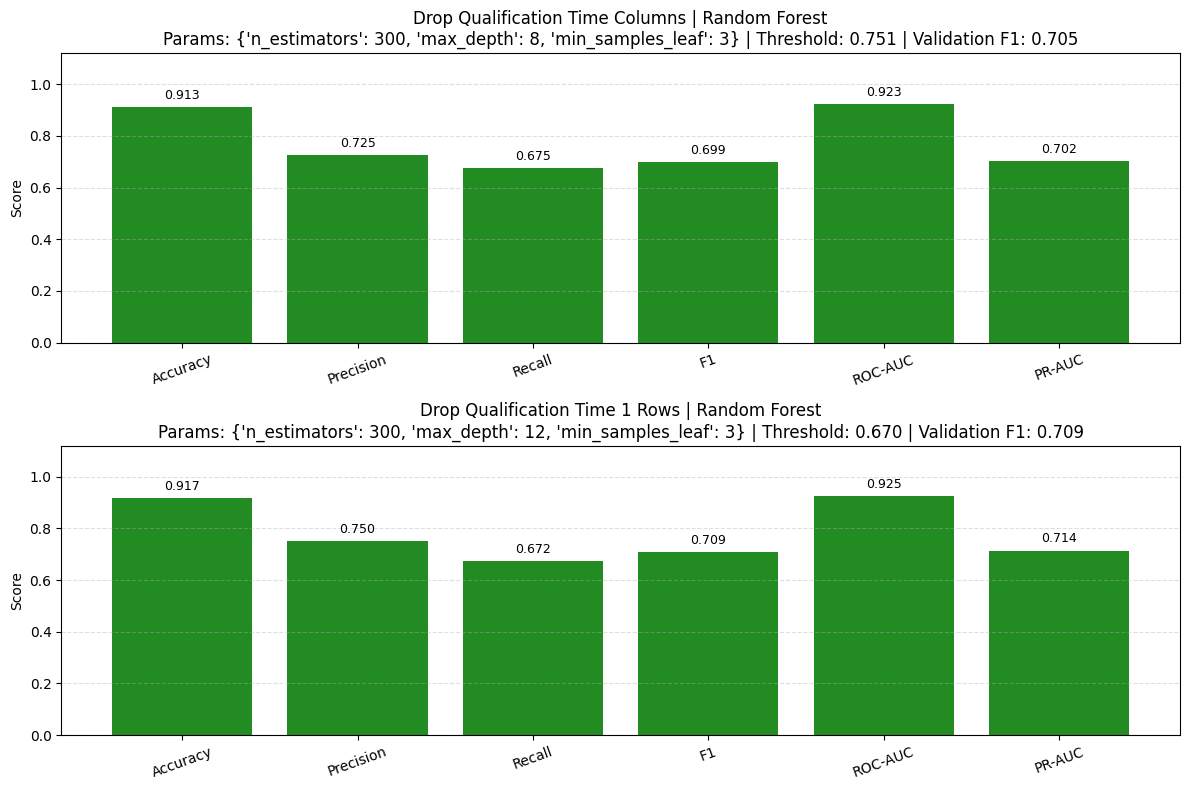

In [48]:
fig, axes = plt.subplots(
    nrows=len(datasets),
    ncols=1,
    figsize=(12, 4 * len(datasets))
)

axes = np.atleast_1d(axes)
all_metrics = {}

all_forest_models = []

for i, (data, num_cols, cat_cols, title) in enumerate(datasets):
    all_metrics[title] = train_random_forest_model(
        data, num_cols, cat_cols,
        ax=axes[i],
        title=title
    )

    all_forest_models.append(all_metrics[title]['model'])

fig.tight_layout()
plt.show()

## **Neural Network**

In [49]:
def train_neural_network_model(
	input_data, numeric_cols, categorical_cols,
	ax, loss_ax, accuracy_ax, title
):
	import numpy as np
	import tensorflow as tf

	from sklearn.compose import ColumnTransformer
	from sklearn.pipeline import Pipeline
	from sklearn.impute import SimpleImputer
	from sklearn.preprocessing import StandardScaler, OneHotEncoder
	from sklearn.utils.class_weight import compute_class_weight
	from sklearn.metrics import (
		accuracy_score, precision_score, recall_score, f1_score,
		roc_auc_score, average_precision_score, precision_recall_curve
	)

	input_data = input_data.copy()
	input_data['podium'] = input_data['positionOrder'].isin([1, 2, 3]).astype(int)

	# Temporal train/validation/test split
	training = input_data[input_data['year'] <= 2019].copy()
	validation = input_data[input_data['year'].between(2020, 2021)].copy()
	testing = input_data[input_data['year'] >= 2022].copy()

	excluded = {'positionOrder', 'podium', 'year'}

	numeric_features = [
		col for col in numeric_cols
		if col in input_data.columns and col not in excluded
	]
	categorical_features = [
		col for col in categorical_cols
		if col in input_data.columns and col not in excluded
	]
	features = numeric_features + categorical_features

	x_train, y_train = training[features], training['podium']
	x_val, y_val = validation[features], validation['podium']
	x_test, y_test = testing[features], testing['podium']

	# Fit preprocessing on training data only
	numeric_transformer = Pipeline([
		('imputer', SimpleImputer(strategy='median')),
		('scaler', StandardScaler())
	])

	categorical_transformer = Pipeline([
		('imputer', SimpleImputer(strategy='most_frequent')),
		('encoder', OneHotEncoder(
			handle_unknown='ignore',
			sparse_output=False
		))
	])

	transformers = []

	if numeric_features:
		transformers.append(
			('numerical', numeric_transformer, numeric_features)
		)

	if categorical_features:
		transformers.append(
			('categorical', categorical_transformer, categorical_features)
		)

	preprocessor = ColumnTransformer(transformers)

	x_train = preprocessor.fit_transform(x_train)
	x_val = preprocessor.transform(x_val)
	x_test = preprocessor.transform(x_test)

	# Balance the classes in the training data
	classes = np.unique(y_train)
	class_weights = compute_class_weight(
		class_weight='balanced',
		classes=classes,
		y=y_train
	)
	class_weight_dict = dict(zip(classes, class_weights))

	# Candidate configurations
	param_combinations = [
		{
			'hidden_layers': (64, 32),
			'learning_rate': 0.001,
			'weight_decay': 0.0001,
			'dropout': 0.1
		},
		{
			'hidden_layers': (32, 16),
			'learning_rate': 0.001,
			'weight_decay': 0.001,
			'dropout': 0.2
		},
		{
			'hidden_layers': (128, 64),
			'learning_rate': 0.0003,
			'weight_decay': 0.0001,
			'dropout': 0.1
		}
	]

	epochs = 150
	batch_size = 32
	patience = 10
	random_state = 42

	best_model = None
	best_params = None
	best_threshold = 0.5
	best_val_f1 = -1
	best_history = None

	# Train and select using validation F1
	for params in param_combinations:
		tf.keras.utils.set_random_seed(random_state)

		model = tf.keras.Sequential()
		model.add(tf.keras.Input(shape=(x_train.shape[1],)))

		for nodes in params['hidden_layers']:
			model.add(tf.keras.layers.Dense(nodes, activation='relu'))
			model.add(tf.keras.layers.Dropout(params['dropout']))

		model.add(tf.keras.layers.Dense(1, activation='sigmoid'))

		model.compile(
			optimizer=tf.keras.optimizers.AdamW(
				learning_rate=params['learning_rate'],
				weight_decay=params['weight_decay']
			),
			loss=tf.keras.losses.BinaryCrossentropy(),
			metrics=[
				tf.keras.metrics.BinaryAccuracy(name='binary_accuracy')
			]
		)

		early_stopping = tf.keras.callbacks.EarlyStopping(
			monitor='val_loss',
			patience=patience,
			restore_best_weights=True
		)

		history = model.fit(
			x_train,
			y_train,
			validation_data=(x_val, y_val),
			epochs=epochs,
			batch_size=batch_size,
			class_weight=class_weight_dict,
			callbacks=[early_stopping],
			verbose=0
		)

		val_prob = model.predict(x_val, verbose=0).ravel()

		if y_val.nunique() == 2:
			precision, recall, thresholds = precision_recall_curve(
				y_val, val_prob
			)

			val_f1_scores = (
				2 * precision[:-1] * recall[:-1]
				/ (precision[:-1] + recall[:-1] + 1e-12)
			)

			best_idx = np.argmax(val_f1_scores)
			threshold = thresholds[best_idx]
			val_f1 = val_f1_scores[best_idx]
		else:
			threshold = 0.5
			val_pred = (val_prob >= threshold).astype(int)
			val_f1 = f1_score(
				y_val, val_pred, zero_division=0
			)

		# Keep the best model and its corresponding history
		if val_f1 > best_val_f1:
			best_val_f1 = val_f1
			best_model = model
			best_params = params.copy()
			best_threshold = threshold
			best_history = history.history.copy()

	# Evaluate the selected model on the test set
	test_prob = best_model.predict(x_val, verbose=0).ravel()
	test_pred = (test_prob >= best_threshold).astype(int)

	metrics = {
		'Accuracy': accuracy_score(y_val, test_pred),
		'Precision': precision_score(
			y_val, test_pred, zero_division=0
		),
		'Recall': recall_score(
			y_val, test_pred, zero_division=0
		),
		'F1': f1_score(y_val, test_pred, zero_division=0),
		'ROC-AUC': (
			roc_auc_score(y_val, test_prob)
			if y_val.nunique() == 2 else np.nan
		),
		'PR-AUC': (
			average_precision_score(y_val, test_prob)
			if y_val.nunique() == 2 else np.nan
		)
	}

	# Plot test metrics
	ax.bar(
		metrics.keys(),
		metrics.values(),
		color='darkorange'
	)
	ax.set_title(
		f'{title} | Neural Network\n'
		f'Layers: {best_params["hidden_layers"]} | '
		f'LR: {best_params["learning_rate"]} | '
		f'Weight decay: {best_params["weight_decay"]} | '
		f'Dropout: {best_params["dropout"]}\n'
		f'Threshold: {best_threshold:.3f} | '
		f'Validation F1: {best_val_f1:.3f}',
		fontsize=10
	)
	ax.set_ylabel('Score')
	ax.set_ylim(0, 1.12)
	ax.tick_params(axis='x', rotation=20)
	ax.grid(axis='y', linestyle='--', alpha=0.4)

	for i, value in enumerate(metrics.values()):
		if not np.isnan(value):
			ax.text(
				i, value + 0.02, f'{value:.3f}',
				ha='center', va='bottom', fontsize=9
			)

	# Plot training and validation loss
	loss_ax.plot(best_history['loss'], label='Training Loss')
	loss_ax.plot(best_history['val_loss'], label='Validation Loss')
	loss_ax.set_title(f'{title} | Binary Cross-Entropy Loss')
	loss_ax.set_xlabel('Epoch')
	loss_ax.set_ylabel('Log Loss')
	loss_ax.legend()
	loss_ax.grid(axis='y', linestyle='--', alpha=0.4)

	# Plot training and validation accuracy
	accuracy_ax.plot(
		best_history['binary_accuracy'],
		label='Training Accuracy'
	)
	accuracy_ax.plot(
		best_history['val_binary_accuracy'],
		label='Validation Accuracy'
	)
	accuracy_ax.set_title(f'{title} | Accuracy')
	accuracy_ax.set_xlabel('Epoch')
	accuracy_ax.set_ylabel('Accuracy')
	accuracy_ax.set_ylim(0, 1.05)
	accuracy_ax.legend()
	accuracy_ax.grid(axis='y', linestyle='--', alpha=0.4)

	return {
		'model_type': 'KerasNeuralNetwork',
		'best_params': best_params,
		'best_threshold': float(best_threshold),
		'validation_f1': float(best_val_f1),
		'test_metrics': metrics,
		'tested_params': param_combinations.copy(),
		'epochs': epochs,
		'batch_size': batch_size,
		'early_stopping_patience': patience,
		'random_state': random_state,
		'class_weight': class_weight_dict,
		'training_history': best_history,
		'model': best_model,
		'preprocessor': preprocessor
	}

2026-10-15 18:04:53.935758: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


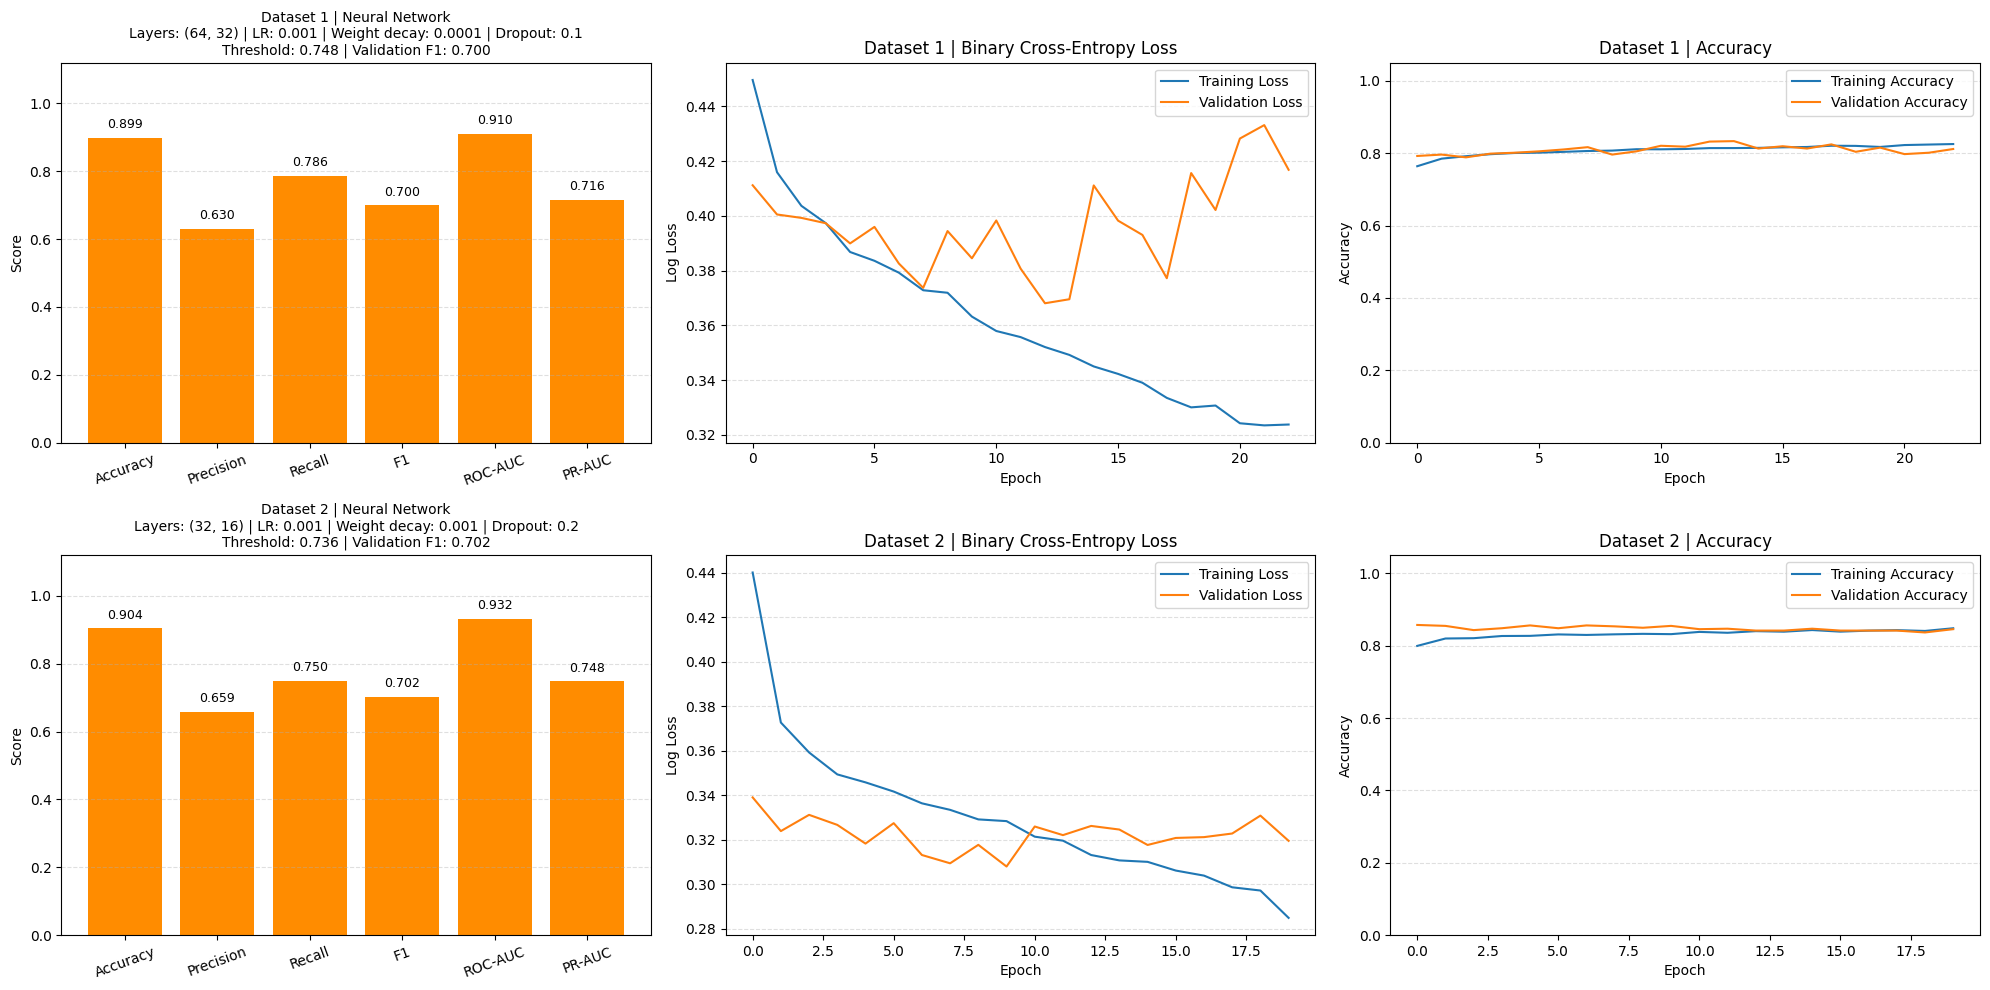

In [50]:
fig, axes = plt.subplots(
	nrows=len(datasets),
	ncols=3,
	figsize=(20, 5 * len(datasets)),
	squeeze=False
)

results = []
all_neural_models = []

for i, dataset in enumerate(datasets):
    result = train_neural_network_model(
        dataset[0],
        numeric_cols,
        categorical_cols,
        axes[i, 0],
        axes[i, 1],
        axes[i, 2],
        f'Dataset {i + 1}'
    )
    results.append(result)
    all_neural_models.append(result['model'])

fig.tight_layout()
plt.show()

# **Experiments**

In [51]:
drop_qual_features_variant = dropped_qual_time_rows.drop(columns= ['q1', 'position'])

drop_pit_stop_features_variant = dropped_qual_time_rows.drop(columns= ['avg_stop_duration_before_race', 'avg_stops_per_race_before_race', 'avg_stop_duration_previous_season', 'avg_stops_per_race_previous_season'])

drop_pit_stop_and_qual_features_variant = dropped_qual_time_rows.drop(columns= ['q1', 'position', 'avg_stop_duration_before_race', 'avg_stops_per_race_before_race', 'avg_stop_duration_previous_season', 'avg_stops_per_race_previous_season'])

In [52]:
experimental_datasets = [
    (drop_qual_features_variant, numeric_cols, categorical_cols, 'Drop Qualification Features'),
    (drop_pit_stop_features_variant, numeric_cols, categorical_cols, 'Drop Pit Stop Features'),
    (drop_pit_stop_and_qual_features_variant, numeric_cols, categorical_cols, 'Drop Qualification and Pit Stop Features'),
]

#### **Logistic Regression**

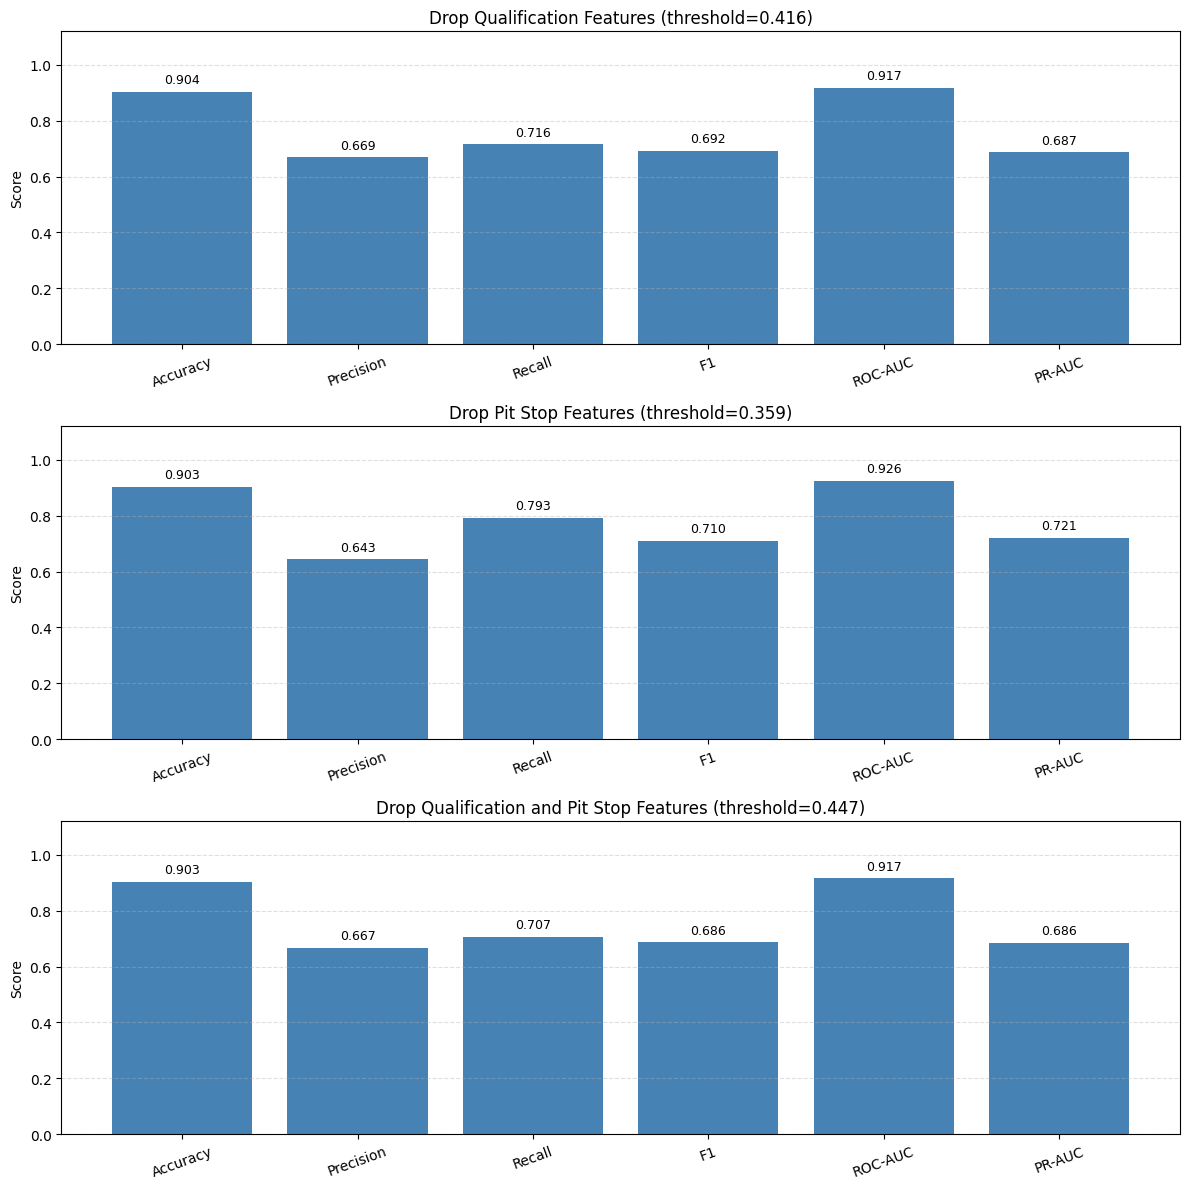

In [53]:
fig, axes = plt.subplots(
    nrows=len(experimental_datasets),
    ncols=1,
    figsize=(12, 4 * len(experimental_datasets))
)

axes = np.atleast_1d(axes)
all_metrics = {}


for i, (data, num_cols, cat_cols, title) in enumerate(experimental_datasets):
    all_metrics[title] = train_logistic_regression_model(
        data, num_cols, cat_cols,
        ax=axes[i],
        title=title
    )

fig.tight_layout()
plt.show()

#### **Random Forest**

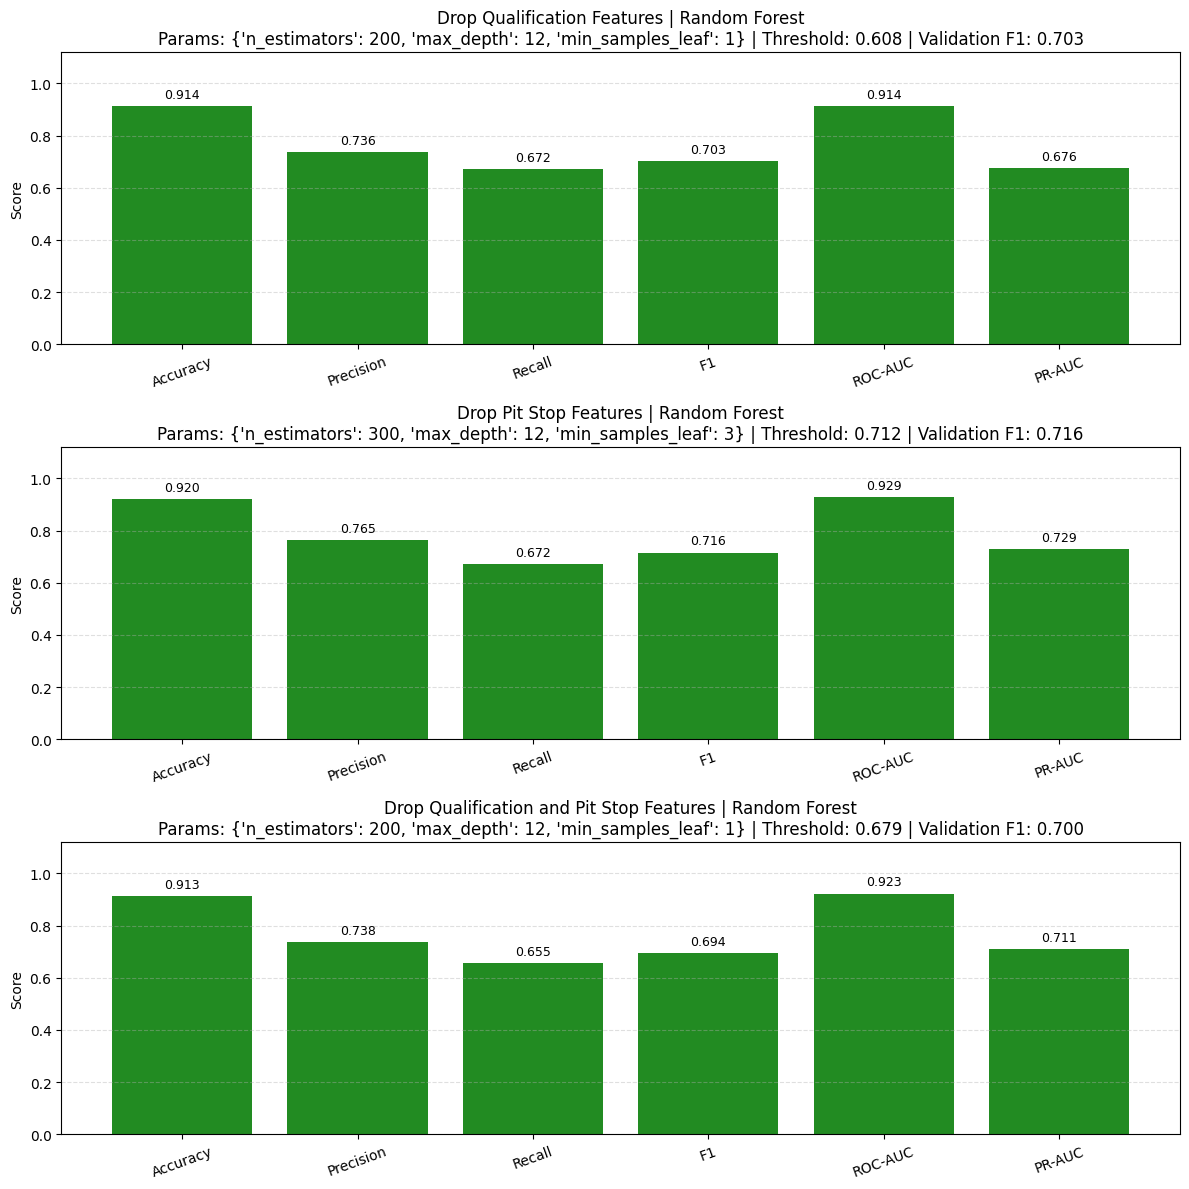

In [54]:
fig, axes = plt.subplots(
    nrows=len(experimental_datasets),
    ncols=1,
    figsize=(12, 4 * len(experimental_datasets))
)

axes = np.atleast_1d(axes)
all_metrics = {}

for i, (data, num_cols, cat_cols, title) in enumerate(experimental_datasets):
    all_metrics[title] = train_random_forest_model(
        data, num_cols, cat_cols,
        ax=axes[i],
        title=title
    )


fig.tight_layout()
plt.show()

#### **Neural Network**

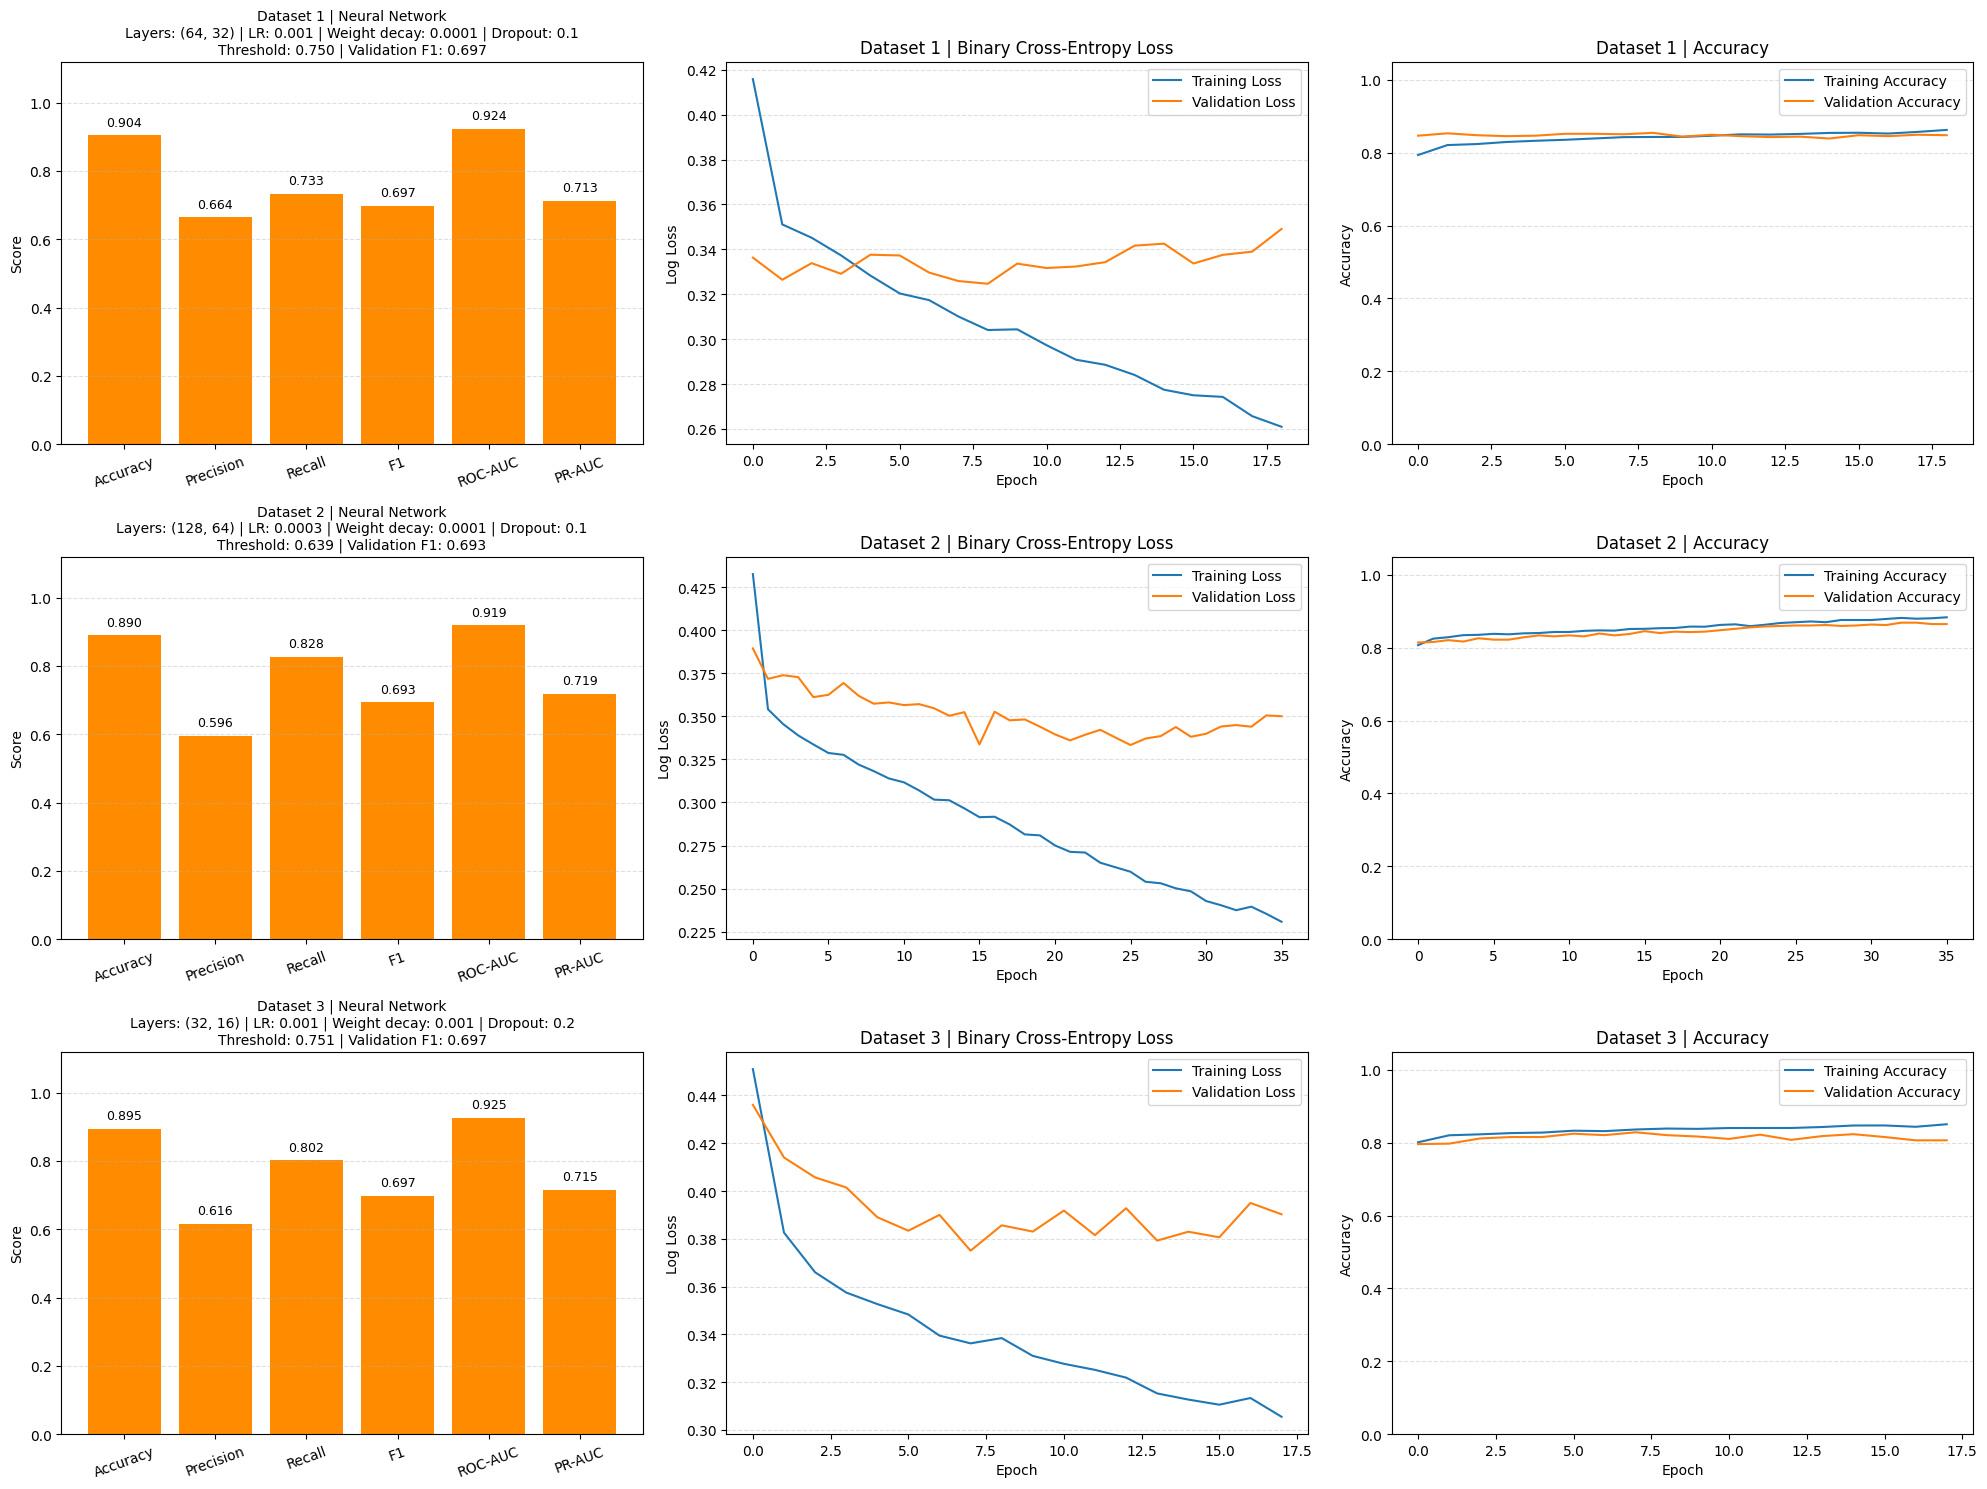

In [55]:
fig, axes = plt.subplots(
	nrows=len(experimental_datasets),
	ncols=3,
	figsize=(20, 5 * len(experimental_datasets)),
	squeeze=False
)

results = []


for i, dataset in enumerate(experimental_datasets):
    result = train_neural_network_model(
		dataset[0],
		numeric_cols,
		categorical_cols,
		axes[i, 0],
		axes[i, 1],
		axes[i, 2],
		f'Dataset {i + 1}'
	)
    results.append(result)
    

fig.tight_layout()
plt.show()

In [56]:
final_models = [all_logistic_models[1], all_forest_models[1], all_neural_models[1]]

Model input shape: (1346, 90)


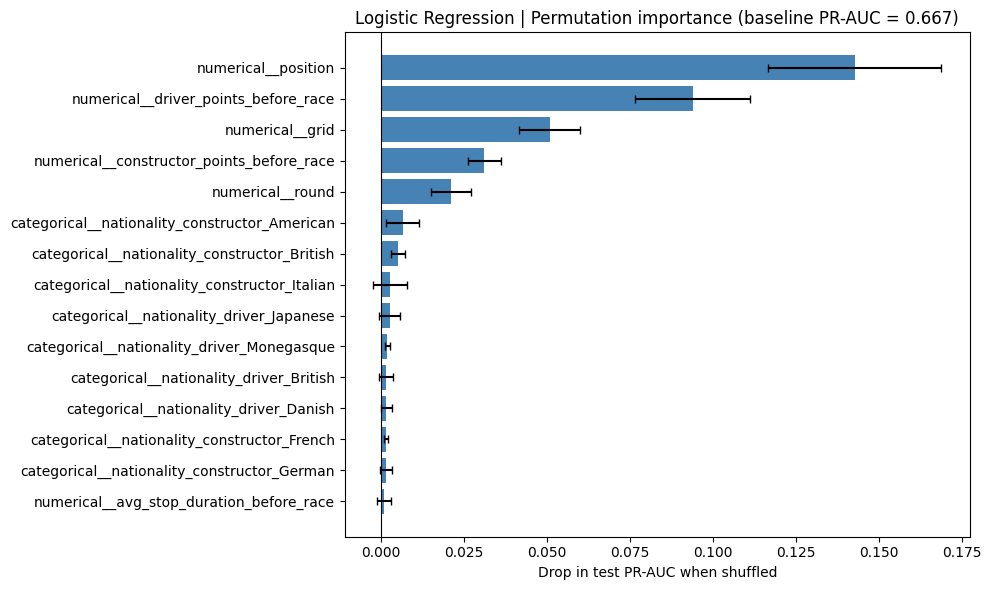

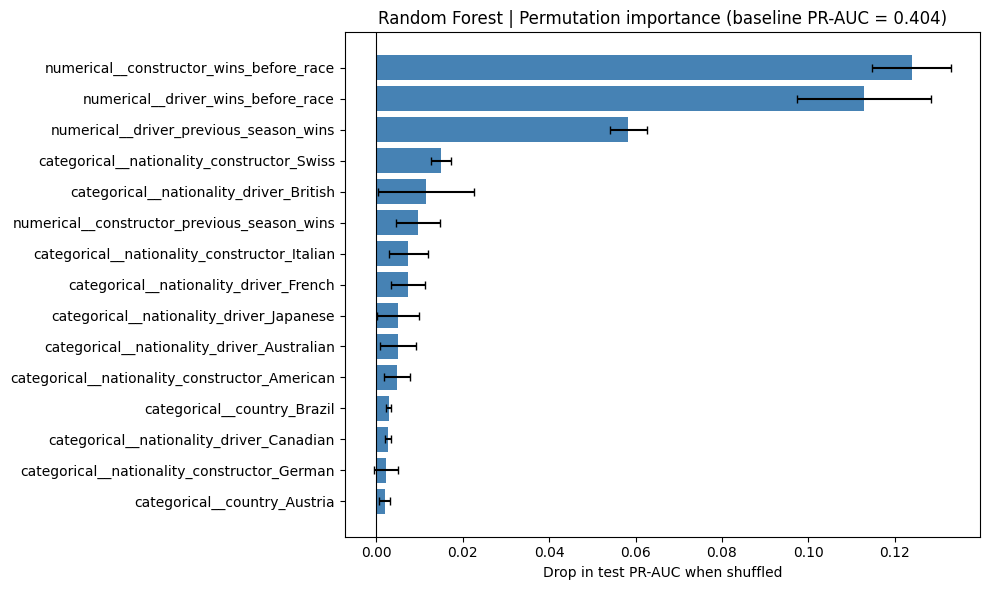

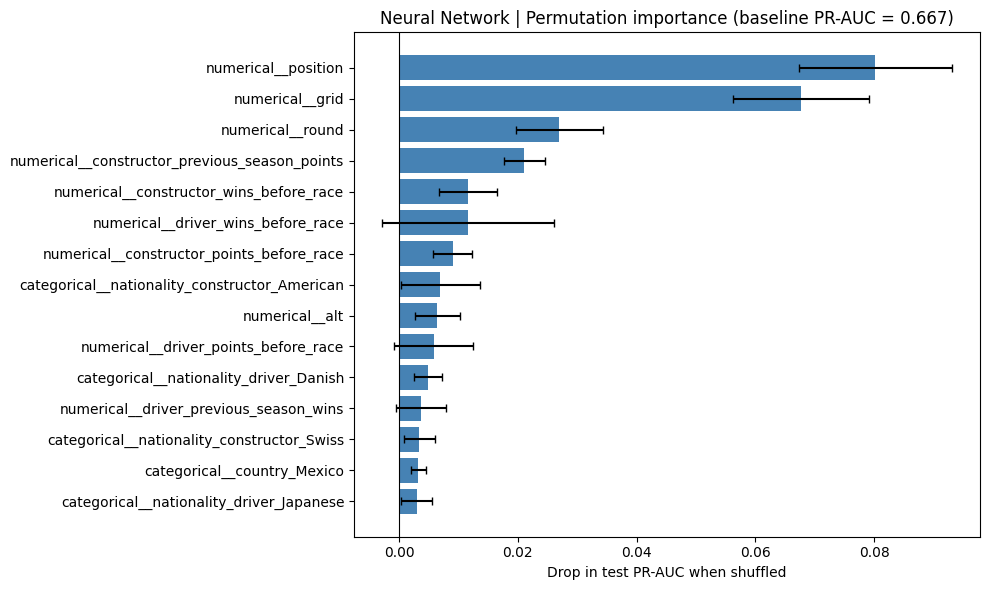

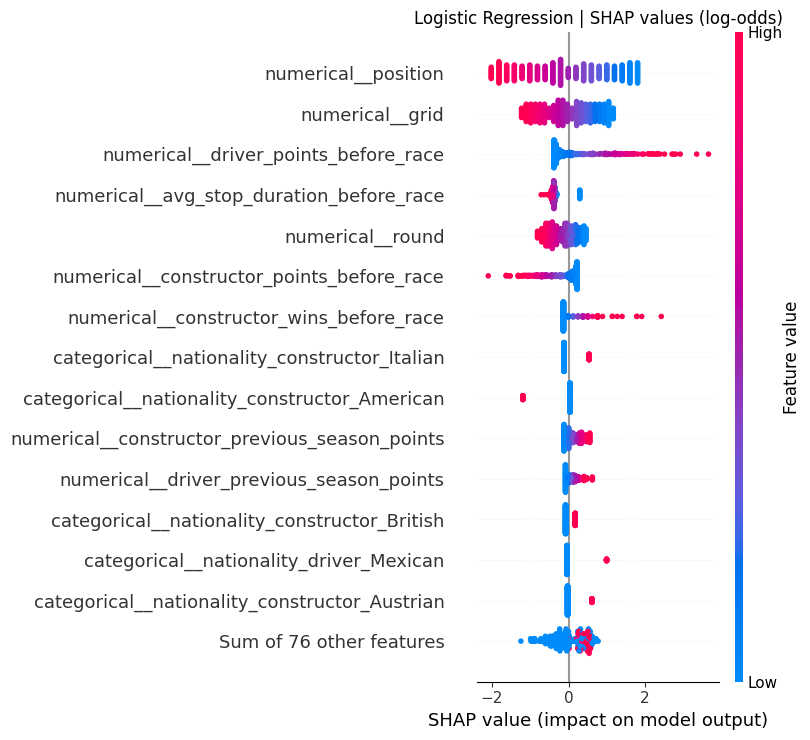

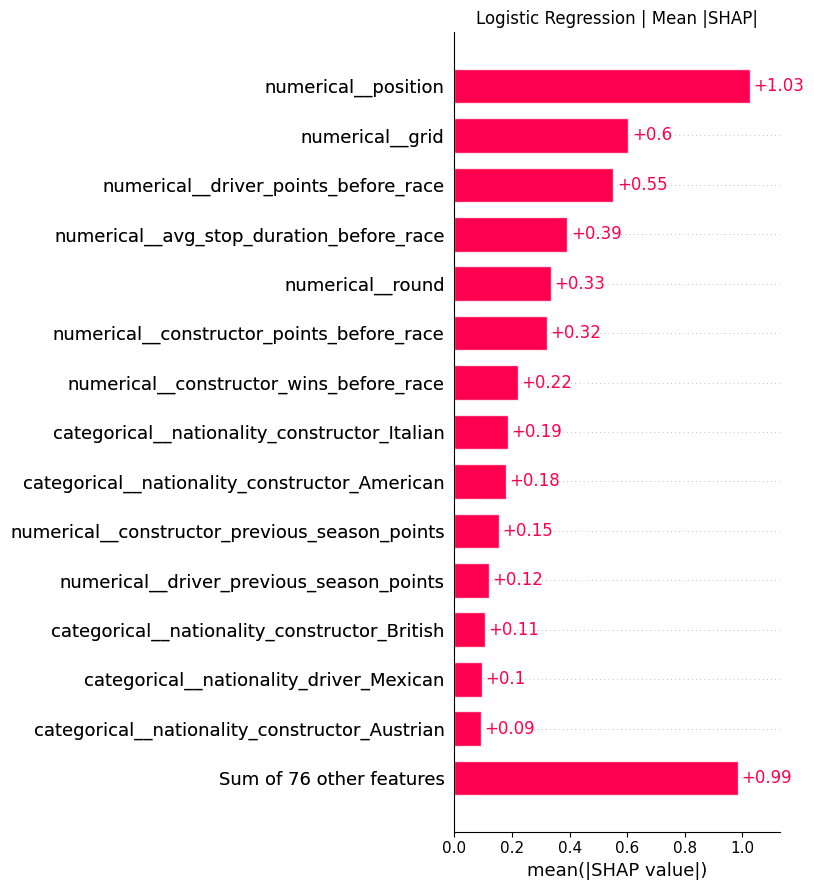

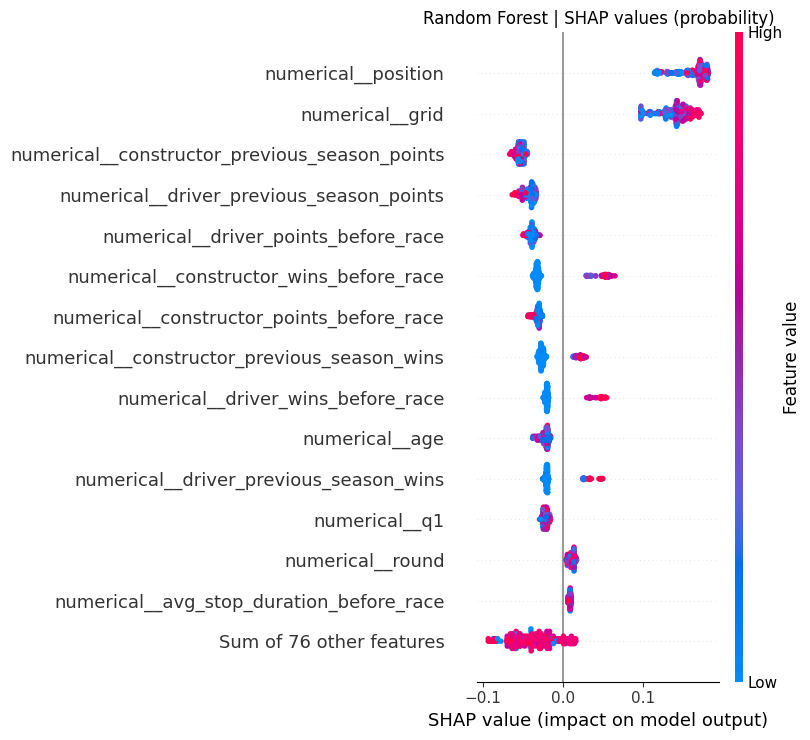

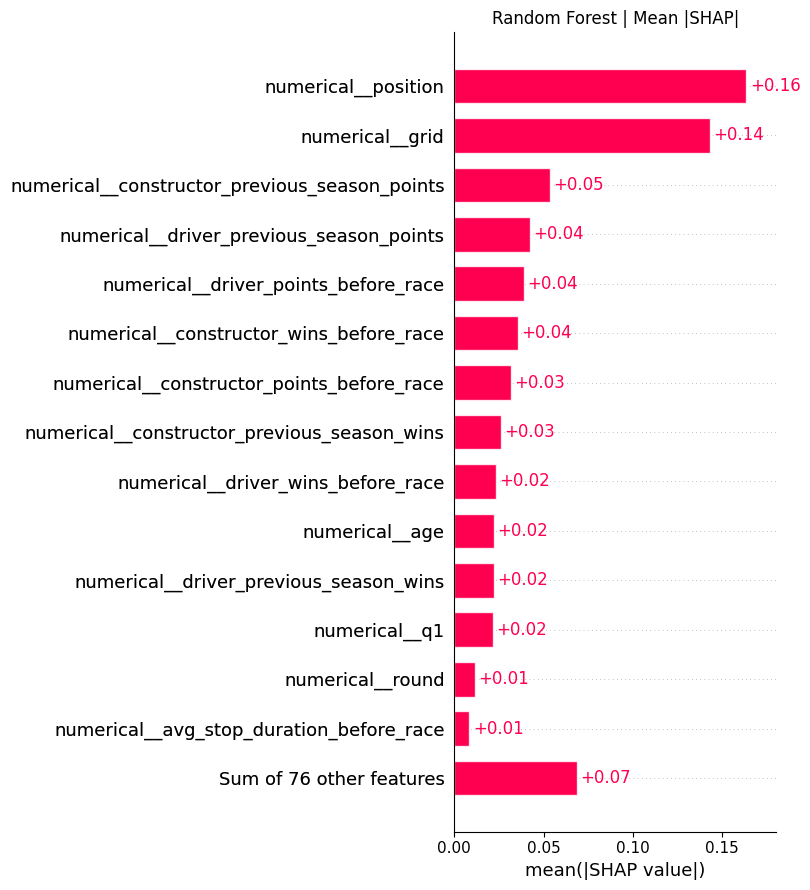

PermutationExplainer explainer: 301it [00:14, 13.51it/s]                         


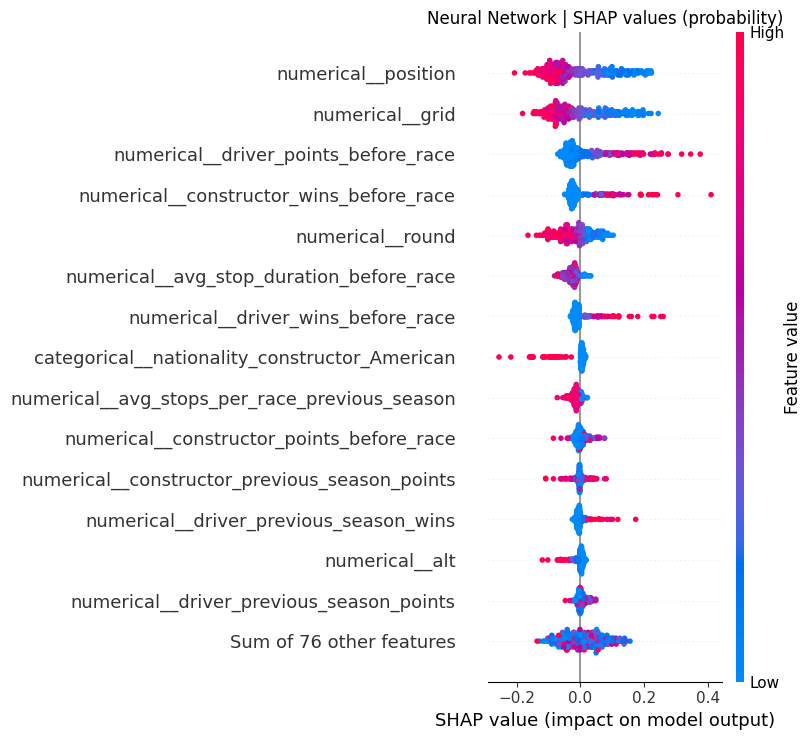

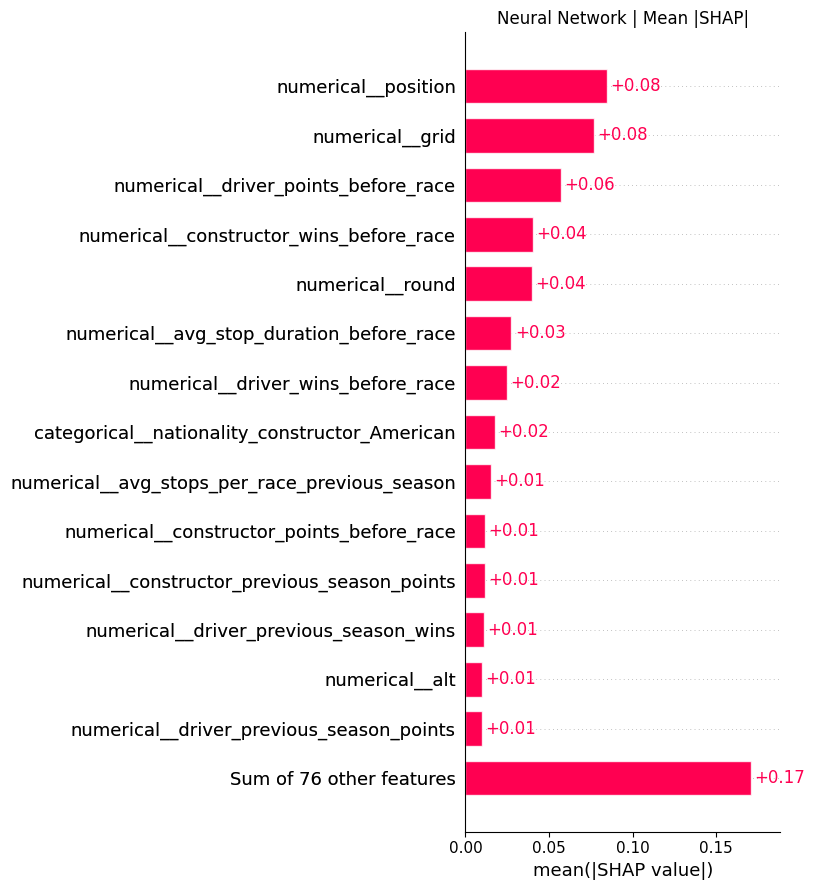

Explained row: year 2022 | round 1 | grid 1 | finished P1
Logistic Regression podium probability: 0.77


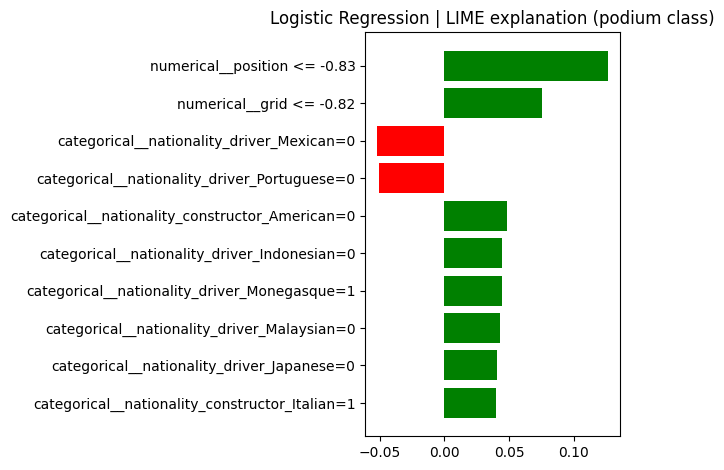

Random Forest podium probability: 0.513


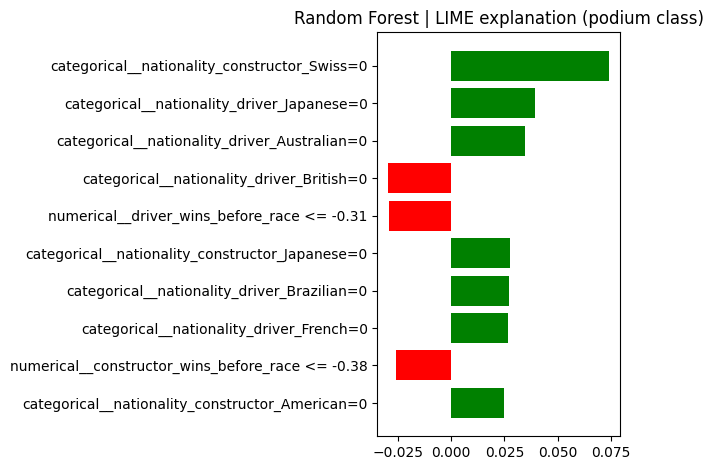

Neural Network podium probability: 0.933


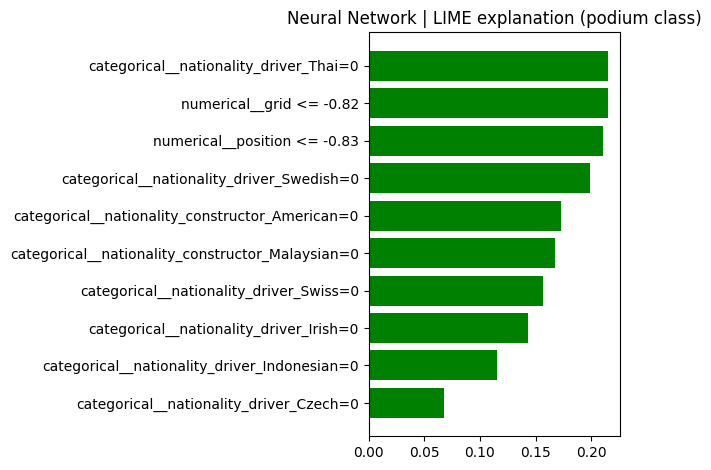

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import average_precision_score

# ---------------- 0. Setup ----------------
log_reg_model = final_models[0]
rf_model = final_models[1]
nn_model = final_models[2]

final_data = dropped_qual_time_rows.copy()
final_data['podium'] = final_data['positionOrder'].isin([1, 2, 3]).astype(int)
training = final_data[final_data['year'] <= 2019]
testing = final_data[final_data['year'] >= 2022]

excluded = ['positionOrder', 'podium', 'year']
numeric_features = [c for c in dict.fromkeys(numeric_cols) if c in final_data.columns and c not in excluded]
categorical_features = [c for c in dict.fromkeys(categorical_cols) if c in final_data.columns and c not in excluded]
features = numeric_features + categorical_features

num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
preprocessor = ColumnTransformer([('numerical', num_pipe, numeric_features), ('categorical', cat_pipe, categorical_features)])

x_train = preprocessor.fit_transform(training[features])
x_test = preprocessor.transform(testing[features])
y_test = testing['podium'].to_numpy()
feature_names = list(preprocessor.get_feature_names_out())
print('Model input shape:', x_test.shape)


def lr_predict(X):
    return log_reg_model.predict_proba(X)[:, 1]


def rf_predict(X):
    return rf_model.predict_proba(X)[:, 1]


def nn_predict(X):
    return nn_model(np.asarray(X, dtype='float32'), training=False).numpy().ravel()


def nn_predict_proba(X):
    p = nn_predict(X)
    return np.column_stack([1 - p, p])


# ---------------- 1. Permutation importance ----------------
def permutation_importance_pr_auc(predict_fn, X, y, n_repeats=5, seed=42):
    rng = np.random.default_rng(seed)
    baseline = average_precision_score(y, predict_fn(X))
    drops = np.zeros((X.shape[1], n_repeats))
    for j in range(X.shape[1]):
        for r in range(n_repeats):
            X_perm = X.copy()
            X_perm[:, j] = rng.permutation(X_perm[:, j])
            drops[j, r] = baseline - average_precision_score(y, predict_fn(X_perm))
    result = pd.DataFrame({'feature': feature_names, 'importance_mean': drops.mean(axis=1), 'importance_std': drops.std(axis=1)})
    return result.sort_values('importance_mean', ascending=False), baseline


def plot_permutation_importance(importance, baseline, title):
    top = importance.head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top['feature'], top['importance_mean'], xerr=top['importance_std'], color='steelblue', capsize=3)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Drop in test PR-AUC when shuffled')
    ax.set_title(title + ' | Permutation importance (baseline PR-AUC = ' + str(round(baseline, 3)) + ')')
    fig.tight_layout()
    plt.show()


lr_importance, lr_baseline = permutation_importance_pr_auc(lr_predict, x_test, y_test)
plot_permutation_importance(lr_importance, lr_baseline, 'Logistic Regression')

rf_importance, rf_baseline = permutation_importance_pr_auc(rf_predict, x_test, y_test)
plot_permutation_importance(rf_importance, rf_baseline, 'Random Forest')

nn_importance, nn_baseline = permutation_importance_pr_auc(nn_predict, x_test, y_test)
plot_permutation_importance(nn_importance, nn_baseline, 'Neural Network')


# ---------------- 2. SHAP ----------------
rng = np.random.default_rng(42)
background = x_train[rng.choice(len(x_train), 100, replace=False)]
x_shap = x_test[rng.choice(len(x_test), 300, replace=False)]

# Logistic Regression (log-odds)
lr_explainer = shap.LinearExplainer(log_reg_model, background)
lr_shap = lr_explainer(x_shap)
lr_shap.feature_names = feature_names

plt.figure()
shap.plots.beeswarm(lr_shap, max_display=15, show=False)
plt.title('Logistic Regression | SHAP values (log-odds)')
plt.tight_layout()
plt.show()

plt.figure()
shap.plots.bar(lr_shap, max_display=15, show=False)
plt.title('Logistic Regression | Mean |SHAP|')
plt.tight_layout()
plt.show()

# Random Forest (probability)
rf_explainer = shap.TreeExplainer(rf_model)
rf_shap = rf_explainer(x_shap, check_additivity=False)
rf_shap.feature_names = feature_names
if rf_shap.values.ndim == 3:
    rf_shap = rf_shap[:, :, 1]

plt.figure()
shap.plots.beeswarm(rf_shap, max_display=15, show=False)
plt.title('Random Forest | SHAP values (probability)')
plt.tight_layout()
plt.show()

plt.figure()
shap.plots.bar(rf_shap, max_display=15, show=False)
plt.title('Random Forest | Mean |SHAP|')
plt.tight_layout()
plt.show()

# Neural Network (probability)
nn_masker = shap.maskers.Independent(background)
nn_explainer = shap.Explainer(nn_predict, nn_masker, feature_names=feature_names, algorithm='permutation', seed=42)
nn_shap = nn_explainer(x_shap, max_evals=2 * x_shap.shape[1] + 1)

plt.figure()
shap.plots.beeswarm(nn_shap, max_display=15, show=False)
plt.title('Neural Network | SHAP values (probability)')
plt.tight_layout()
plt.show()

plt.figure()
shap.plots.bar(nn_shap, max_display=15, show=False)
plt.title('Neural Network | Mean |SHAP|')
plt.tight_layout()
plt.show()


# ---------------- 3. LIME (one test row, same row for all models) ----------------
categorical_indices = [i for i, name in enumerate(feature_names) if name.startswith('categorical__')]
lime_explainer = LimeTabularExplainer(x_train, feature_names=feature_names, class_names=['No podium', 'Podium'], categorical_features=categorical_indices, mode='classification', discretize_continuous=True, random_state=42)

row_idx = np.where(y_test == 1)[0][0]
row_info = testing.iloc[row_idx]
print('Explained row: year', row_info['year'], '| round', row_info['round'], '| grid', row_info['grid'], '| finished P' + str(row_info['positionOrder']))

# Logistic Regression
lr_lime = lime_explainer.explain_instance(x_test[row_idx], log_reg_model.predict_proba, num_features=10, num_samples=5000)
print('Logistic Regression podium probability:', round(lr_predict(x_test[[row_idx]])[0], 3))
lr_lime.as_pyplot_figure(label=1)
plt.title('Logistic Regression | LIME explanation (podium class)')
plt.tight_layout()
plt.show()

# Random Forest
rf_lime = lime_explainer.explain_instance(x_test[row_idx], rf_model.predict_proba, num_features=10, num_samples=5000)
print('Random Forest podium probability:', round(rf_predict(x_test[[row_idx]])[0], 3))
rf_lime.as_pyplot_figure(label=1)
plt.title('Random Forest | LIME explanation (podium class)')
plt.tight_layout()
plt.show()

# Neural Network
nn_lime = lime_explainer.explain_instance(x_test[row_idx], nn_predict_proba, num_features=10, num_samples=5000)
print('Neural Network podium probability:', round(nn_predict(x_test[[row_idx]])[0], 3))
nn_lime.as_pyplot_figure(label=1)
plt.title('Neural Network | LIME explanation (podium class)')
plt.tight_layout()
plt.show()